# TinyML on the ESP32 training, testing and exporting 9 models

## 1. Setup and configuration

In [240]:
import os, json, time, math, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras

SEED = 2026
N_FEATURES = 20 # featreus kept after feature selection
DATA_FILE = Path("data/train_test_network.csv")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

ESP32_DIR = Path("esp32")

N_DEVICE_TEST = 400
N_SERIAL_TEST = 4000
# Grid search (hyperparameter tuning)
TUNING_AVERAGE   = "macro"    # F1 used to compare settings on the validation set:
                              #   "micro"  = over all rows (with one label per row this equals accuracy)
                              #   "binary" = attack class only,  "macro" = average of both classes
TUNING_TOLERANCE = 0.001      # pick the SMALLEST model within 0.001 (= 0.1 %-points) of the best F1
                              #   0 = always the best F1, whatever the size
TUNING_DIR = RESULTS_DIR / "tuning"

NN_EPOCHS      = 30
NN_BATCH       = 256

np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)


## 2. Load the TON_IoT network dataset

In [241]:
df = pd.read_csv(DATA_FILE, low_memory=False)

print(df.shape)
display(df.head())
print("\nlabel:\n", df["label"].value_counts())
print("\ntype:\n", df["type"].value_counts())

(211043, 44)


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor



label:
 label
1    161043
0     50000
Name: count, dtype: int64

type:
 type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64


## 3. Preprocessing

In [242]:
# Columns we throw away:
#   - IP addresses and source port say WHICH machine, not WHAT it does
#   - dns_query is free text (thousands of different domain names)
DROP_COLUMNS = ["ts", "src_ip", "dst_ip", "src_port", "dns_query"]

LABEL_COLUMNS = ["label", "type"]

# Columns that contain words instead of numbers (e.g. "tcp", "udp")
TEXT_COLUMNS = ["proto", "service", "conn_state",
                "dns_AA", "dns_RD", "dns_RA", "dns_rejected",
                "ssl_version", "ssl_cipher", "ssl_resumed", "ssl_established",
                "ssl_subject", "ssl_issuer",
                "http_method", "http_uri", "http_user_agent",
                "http_orig_mime_types", "http_resp_mime_types",
                "weird_name", "weird_notice"]

NUMBER_COLUMNS = [col for col in df.columns if col not in DROP_COLUMNS + LABEL_COLUMNS + TEXT_COLUMNS]

X_raw = pd.DataFrame()

# Number columns: "-" means "no value", so we use 0
for col in NUMBER_COLUMNS:
    X_raw[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Text columns: give every word a number
# "-" always gets 0, the other words get 1, 2, 3 ... (alphabetical)
# e.g. proto: "-" -> 0, "icmp" -> 1, "tcp" -> 2, "udp" -> 3
encodings = {}  # saved so the ESP32 / gateway can use the same numbers
for col in TEXT_COLUMNS:
    text = df[col].fillna("-").astype(str).str.strip()
    words = sorted(set(text) - {"-"})
    mapping = {"-": 0}
    for number, word in enumerate(words, start=1):
        mapping[word] = number
    X_raw[col] = text.map(mapping)
    encodings[col] = mapping


# Remove columns that have the same value in every row
useless = [col for col in X_raw.columns if X_raw[col].nunique() == 1]
X_raw = X_raw.drop(columns=useless)

# put the columns back in the same order as in the CSV file
X_raw = X_raw[[col for col in df.columns if col in X_raw.columns]]

numeric_cols     = [col for col in NUMBER_COLUMNS if col not in useless]
categorical_cols = [col for col in TEXT_COLUMNS if col not in useless]
print("number columns:", numeric_cols)
print("text columns  :", categorical_cols)
print("removed (same value everywhere):", useless)

y_binary = df["label"].to_numpy()

CLASS_NAMES = ["normal", "attack"]
y_task = y_binary

N_CLASSES = len(CLASS_NAMES)

# Remove duplicate rows (same features AND same label)
rows = X_raw.copy()
rows["y_task"] = y_task
rows["y_binary"] = y_binary
keep = (~rows.duplicated()).to_numpy()

X_raw    = X_raw[keep].reset_index(drop=True)
y_task   = y_task[keep]
y_binary = y_binary[keep]
print(f"\nremoved {(~keep).sum()} duplicates, {len(X_raw)} rows left")

print(pd.Series(y_task).map({0: "normal", 1: "attack"}).value_counts())

number columns: ['dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_trans_depth', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'weird_addl']
text columns  : ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_method', 'http_uri', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']
removed (same value everywhere): []

removed 105849 duplicates, 105194 rows left
attack    81088
normal    24106
Name: count, dtype: int64


### Train / validation / test split, scaling and feature selection
* Stratified **70 / 15 / 15** split.
* **log1p** on heavy-tailed columns (bytes, packets, durations: numeric columns with max > 100). Then **z-score standardisation**, with the statistics computed on the training set only.
* **Feature selection**: the `N_FEATURES` most important features according to an Extra-Trees model trained on the training set. Fewer features means less memory and faster inference on the MCU.

train 73635 | val 15779 | test 15780


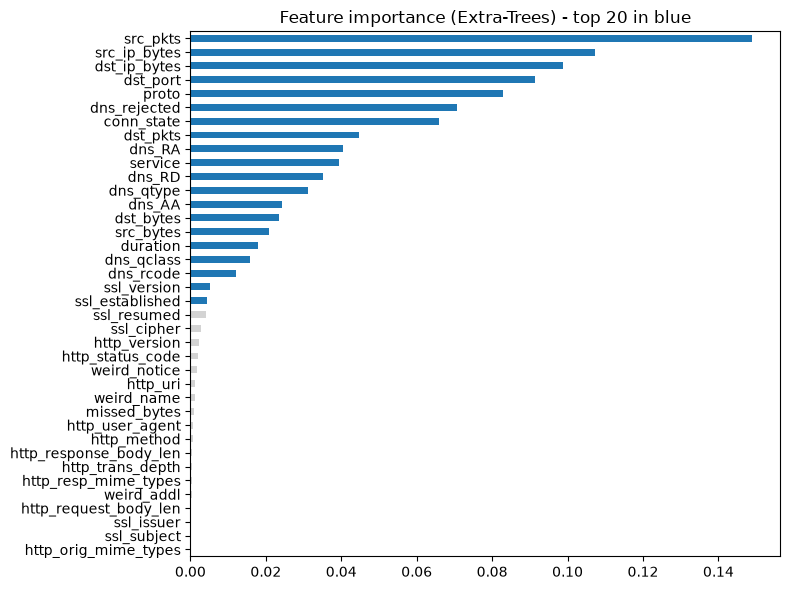

selected features: ['src_pkts', 'src_ip_bytes', 'dst_ip_bytes', 'dst_port', 'proto', 'dns_rejected', 'conn_state', 'dst_pkts', 'dns_RA', 'service', 'dns_RD', 'dns_qtype', 'dns_AA', 'dst_bytes', 'src_bytes', 'duration', 'dns_qclass', 'dns_rcode', 'ssl_version', 'ssl_established']


In [243]:
idx = np.arange(len(X_raw))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y_task, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y_task[idx_tmp], random_state=SEED)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)}")

all_cols = list(X_raw.columns)
log_cols = [c for c in numeric_cols if X_raw.loc[idx_train, c].max() > 100]

def transform_log(X: pd.DataFrame, cols) -> pd.DataFrame:
    X = X.copy()
    for c in cols:
        X[c] = np.log1p(np.clip(X[c].values, 0, None))
    return X

Xl_train = transform_log(X_raw.loc[idx_train], log_cols)
mean_all = Xl_train.mean()
std_all = Xl_train.std(ddof=0).replace(0, 1.0)

# feature importance on a (sub)sample of the training data
sub = np.random.RandomState(SEED).choice(len(idx_train), min(100_000, len(idx_train)), replace=False)
et = ExtraTreesClassifier(n_estimators=300, max_depth=16, n_jobs=-1, random_state=SEED)
et.fit(((Xl_train - mean_all) / std_all).values[sub], y_task[idx_train][sub])
importance = pd.Series(et.feature_importances_, index=all_cols).sort_values(ascending=False)
SELECTED = list(importance.index[:N_FEATURES])

fig, ax = plt.subplots(figsize=(8, 6))
importance.iloc[::-1].plot.barh(ax=ax, color=["tab:blue" if c in SELECTED else "lightgray" for c in importance.index[::-1]])
ax.set_title(f"Feature importance (Extra-Trees) - top {N_FEATURES} in blue")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150); plt.show()
print("selected features:", SELECTED)

In [244]:
FEAT_LOG  = np.array([c in log_cols for c in SELECTED], dtype=np.uint8)
FEAT_MEAN = mean_all[SELECTED].to_numpy(dtype=np.float64)
FEAT_STD  = std_all[SELECTED].to_numpy(dtype=np.float64)

def preprocess(raw: np.ndarray) -> np.ndarray:
    """Same as preprocess() in main/preprocess.h on the ESP32."""
    x = raw.astype(np.float64).copy()
    x[:, FEAT_LOG == 1] = np.log1p(np.clip(x[:, FEAT_LOG == 1], 0, None))
    return ((x - FEAT_MEAN) / FEAT_STD).astype(np.float32)

R_train = X_raw.loc[idx_train, SELECTED].to_numpy(dtype=np.float32)
R_val   = X_raw.loc[idx_val,   SELECTED].to_numpy(dtype=np.float32)
R_test  = X_raw.loc[idx_test,  SELECTED].to_numpy(dtype=np.float32)
X_train, X_val, X_test = preprocess(R_train), preprocess(R_val), preprocess(R_test)
y_train, y_val, y_test = y_task[idx_train], y_task[idx_val], y_task[idx_test]
yb_train, yb_val, yb_test = y_binary[idx_train], y_binary[idx_val], y_binary[idx_test]

class_weights = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(class_weights)}
print(X_train.shape, X_val.shape, X_test.shape)

(73635, 20) (15779, 20) (15780, 20)


## 4. Helper functions

In [245]:
results = []        # one row per model -> becomes the comparison table
predictions = {}    # stored predictions -> used for the confusion matrices

def evaluate(name, y_true, y_pred, train_time_s, predict_fn, size_bytes, extra=None):
    """Compute the scores of one model and store them in `results`."""
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0)   # scores for the "attack" class

    # how long does one prediction take on this PC? (average over 2000 samples)
    start = time.perf_counter()
    predict_fn(X_test[:2000])
    pc_time_us = (time.perf_counter() - start) / 2000 * 1e6

    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "size_kb": size_bytes / 1024,      # size of the model on the ESP32
        "pc_infer_us": pc_time_us,
        "train_time_s": train_time_s,
    }
    if extra:                              # optional extra info, e.g. number of tree nodes
        row.update(extra)

    # replace an older result of the same model (if the cell is run twice)
    results[:] = [r for r in results if r["model"] != name]
    results.append(row)
    predictions[name] = (y_true, y_pred)

    print(f"{name}: accuracy={row['accuracy']:.4f}  precision={precision:.4f}  "
          f"recall={recall:.4f}  F1={f1:.4f}  size={row['size_kb']:.1f} KB")


def plot_confusion_matrix(name):
    """Show the confusion matrix of a model that was evaluated before."""
    y_true, y_pred = predictions[name]
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(colorbar=False)
    plt.title(name)
    plt.show()

def c_float(value):
    """Write a number as a C float, e.g. 0.5 -> '0.5f' and 3 -> '3.0f'."""
    text = "%.9g" % float(np.float32(value))   # 9 digits = exact float32 value
    if "." not in text and "e" not in text:
        text += ".0"                            # '3f' is not valid C, '3.0f' is
    return text + "f"

def c_array(name, values, c_type, per_line=10, align=False):
    """Turn a list/array of numbers into a C array, e.g.
       static const float W[3] = { 0.1f, 0.2f, 0.3f };"""
    values = np.asarray(values).ravel()                      # make it 1-D
    if c_type == "float":
        items = [c_float(v) for v in values]
    else:
        items = [str(int(v)) for v in values]

    lines = []
    for i in range(0, len(items), per_line):                # a few numbers per line
        lines.append(", ".join(items[i:i + per_line]))
    body = ",\n    ".join(lines)

    prefix = "alignas(16) " if align else ""                # TFLite models must be aligned
    return f"{prefix}static const {c_type} {name}[{len(values)}] = {{\n    {body}\n}};\n"

def c_int_type(largest_value):
    """Smallest integer type that fits: int16_t saves flash compared to int32_t."""
    return "int16_t" if largest_value < 32767 else "int32_t"

def c_header(title):
    """Text at the top of every generated .h file."""
    return (f"// {title}\n"
            f"// GENERATED by TinyML_models.ipynb - do not edit by hand.\n"
            f"#pragma once\n#include <stdint.h>\n\n")

def write_file(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text)

def pick_test_samples(y, n, seed=SEED):
    """Pick n test rows with the same normal/attack ratio as the test set."""
    rows = np.arange(len(y))
    if n >= len(y):
        return rows
    chosen, _ = train_test_split(rows, train_size=n, stratify=y, random_state=seed)
    return np.sort(chosen)

def export_project(folder, model_name, model_data_h, y_pred):
    """Write the 4 generated .h files + test_set.csv into esp32/<folder>.

    model_data_h : C code with the model parameters (made by the model's own cell)
    y_pred       : the Python model's predictions on X_test (to check the C port)
    """
    main = ESP32_DIR / folder / "main"

    # 1) preprocessing: which features, log yes/no, mean and 1/std
    names = ",\n    ".join(f'"{c}"' for c in SELECTED)
    text = c_header("Preprocessing parameters")
    text += f"#define N_FEATURES {N_FEATURES}\n\n"
    text += f"static const char *const FEATURE_NAMES[N_FEATURES] = {{\n    {names}\n}};\n\n"
    text += "// Integer codes of the text features (0 = '-'):\n"
    for col in SELECTED:
        if col in encodings:
            codes = ", ".join(f"{word}={number}" for word, number in list(encodings[col].items())[:30])
            text += f"//   {col}: {codes}\n"
    text += "\n"
    text += c_array("FEATURE_LOG1P", FEAT_LOG, "uint8_t", per_line=20)
    text += c_array("FEATURE_MEAN", FEAT_MEAN, "float")
    text += c_array("FEATURE_INV_STD", 1.0 / FEAT_STD, "float")
    write_file(main / "preprocess_data.h", text)

    # 2) model info: name and class names
    text = c_header("Model information")
    text += f'#define MODEL_NAME "{model_name}"\n'
    text += f"#define MODEL_N_CLASSES {N_CLASSES}\n"
    text += f"#define N_FEATURES_MODEL {N_FEATURES}\n"
    text += "static const char *const MODEL_CLASS_NAMES[MODEL_N_CLASSES] = {"
    text += ", ".join(f'"{c}"' for c in CLASS_NAMES) + "};\n"
    write_file(main / "model_info.h", text)

    # 3) model parameters (already written as C code by the model's cell)
    write_file(main / "model_data.h", c_header(f"{model_name} parameters") + model_data_h)

    # 4) test samples for the self-test: RAW values, true label, Python prediction
    sel = pick_test_samples(y_test, N_DEVICE_TEST)
    rows = ",\n".join("    {" + ", ".join(c_float(v) for v in R_test[i]) + "}" for i in sel)
    text = c_header("Test samples for the on-device self-test (RAW features)")
    text += f"#define N_TEST {len(sel)}\n\n"
    text += f"static const float TEST_X[N_TEST][{N_FEATURES}] = {{\n{rows}\n}};\n\n"
    text += c_array("TEST_Y", y_test[sel], "uint8_t", per_line=25)
    text += "// prediction of the Python model for the same samples\n"
    text += c_array("TEST_PY_PRED", y_pred[sel], "uint8_t", per_line=25)
    write_file(main / "test_data.h", text)

    # 5) bigger test set as CSV for tools/serial_eval.py
    sel = pick_test_samples(y_test, N_SERIAL_TEST, seed=SEED + 1)
    table = pd.DataFrame(R_test[sel], columns=SELECTED)
    table["label"] = y_test[sel]
    table["python_pred"] = y_pred[sel]
    table.to_csv(ESP32_DIR / folder / "test_set.csv", index=False)

    print(f"  -> exported to {ESP32_DIR / folder}")

# save the preprocessing + text codes once, for a gateway / other programs
ESP32_DIR.mkdir(exist_ok=True)
with open(ESP32_DIR / "feature_encoding.json", "w") as f:
    json.dump({"features": SELECTED,
               "log1p": FEAT_LOG.tolist(),
               "mean": FEAT_MEAN.tolist(),
               "std": FEAT_STD.tolist(),
               "categorical_encodings": {c: encodings[c] for c in SELECTED if c in encodings},
               "classes": CLASS_NAMES}, f, indent=2)
print("wrote", ESP32_DIR / "feature_encoding.json")

wrote esp32/feature_encoding.json


## 4b. Grid search (hyperparameter tuning)
Every model gets a tuning cell right before its own cell. It tries all combinations of a few settings (train on the training set, score on the **validation** set) and picks the smallest model whose F1 is within `TUNING_TOLERANCE` of the best. The model cell then trains the final model with these settings and tests it on the test set. All tries are saved in `results/tuning/`.

In [246]:
# ---------------------------------------------------------------
# 4b Grid search (hyperparameter tuning)
# ---------------------------------------------------------------
# For every model we try all combinations of a few settings:
#   - train on the TRAINING set
#   - score on the VALIDATION set (the test set is NOT used here)
# Then we pick the SMALLEST model whose score is within TUNING_TOLERANCE of the
# best score: on the ESP32 a smaller model is better if it is almost as good.

chosen_params = {}   # model name -> chosen settings (shown in the summary at the end)


def val_score(y_pred):
    """Score of the predictions on the validation set (F1, see TUNING_AVERAGE)."""
    return f1_score(y_val, y_pred, average=TUNING_AVERAGE)


def grid_search(name, grid, train_and_score):
    """Try every combination of the values in `grid` and return the chosen settings.

    grid            : e.g. {"max_depth": [6, 10], "min_samples_leaf": [1, 5]}
                      -> tries (6,1), (6,5), (10,1), (10,5)
    train_and_score : a function(params) that trains a model with these settings
                      and returns (validation score, size on the ESP32 in bytes)
    """
    print(f"Grid search {name}: {len(list(itertools.product(*grid.values())))} combinations")
    tried = []    # the settings of every try (a dict each)
    rows = []     # one row per try -> table
    for values in itertools.product(*grid.values()):
        params = dict(zip(grid.keys(), values))
        start = time.perf_counter()
        score, size_bytes = train_and_score(params)
        seconds = time.perf_counter() - start

        tried.append(params)
        rows.append({**params, "val_f1": score, "size_kb": size_bytes / 1024, "time_s": seconds})
        print(f"  {params}  ->  val F1 {score:.4f}   {size_bytes / 1024:.1f} KB   ({seconds:.1f}s)")

    table = pd.DataFrame(rows)

    # choose: all tries close to the best score, then the smallest of them
    best_score = table["val_f1"].max()
    good_enough = table[table["val_f1"] >= best_score - TUNING_TOLERANCE]
    chosen_row = good_enough.sort_values(["size_kb", "val_f1"], ascending=[True, False]).index[0]
    chosen = tried[chosen_row]
    table["chosen"] = table.index == chosen_row

    # save all tries for the thesis
    TUNING_DIR.mkdir(parents=True, exist_ok=True)
    file_name = name.lower().replace(" ", "_").replace("-", "") + ".csv"
    table.to_csv(TUNING_DIR / file_name, index=False)

    # plot: score vs size of every try, the chosen one in red
    plt.figure(figsize=(6, 3.5))
    plt.scatter(table["size_kb"], table["val_f1"], label="tried")
    plt.scatter(table.loc[chosen_row, "size_kb"], table.loc[chosen_row, "val_f1"],
                color="red", s=80, label="chosen")
    if table["size_kb"].max() > 10 * table["size_kb"].min():
        plt.xscale("log")                       # sizes very different -> log axis
    plt.xlabel("size on the ESP32 (KB)")
    plt.ylabel(f"validation F1 ({TUNING_AVERAGE})")
    plt.title(f"Grid search: {name}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"best val F1 {best_score:.4f} -> chosen {chosen} "
          f"(val F1 {table.loc[chosen_row, 'val_f1']:.4f}, {table.loc[chosen_row, 'size_kb']:.1f} KB)")
    print(f"all tries saved to {TUNING_DIR / file_name}")
    chosen_params[name] = chosen
    return chosen

### 5.1 Decision Tree 

Grid search Decision Tree: 35 combinations
  {'max_depth': 4, 'min_samples_leaf': 1}  ->  val F1 0.9783   0.4 KB   (0.1s)
  {'max_depth': 4, 'min_samples_leaf': 2}  ->  val F1 0.9783   0.4 KB   (0.1s)
  {'max_depth': 4, 'min_samples_leaf': 5}  ->  val F1 0.9783   0.4 KB   (0.1s)
  {'max_depth': 4, 'min_samples_leaf': 10}  ->  val F1 0.9782   0.4 KB   (0.1s)
  {'max_depth': 4, 'min_samples_leaf': 20}  ->  val F1 0.9780   0.4 KB   (0.1s)
  {'max_depth': 6, 'min_samples_leaf': 1}  ->  val F1 0.9908   1.2 KB   (0.1s)
  {'max_depth': 6, 'min_samples_leaf': 2}  ->  val F1 0.9908   1.2 KB   (0.1s)
  {'max_depth': 6, 'min_samples_leaf': 5}  ->  val F1 0.9908   1.2 KB   (0.1s)
  {'max_depth': 6, 'min_samples_leaf': 10}  ->  val F1 0.9900   1.1 KB   (0.1s)
  {'max_depth': 6, 'min_samples_leaf': 20}  ->  val F1 0.9899   1.1 KB   (0.1s)
  {'max_depth': 8, 'min_samples_leaf': 1}  ->  val F1 0.9934   2.6 KB   (0.1s)
  {'max_depth': 8, 'min_samples_leaf': 2}  ->  val F1 0.9933   2.5 KB   (0.1s)
  {'m

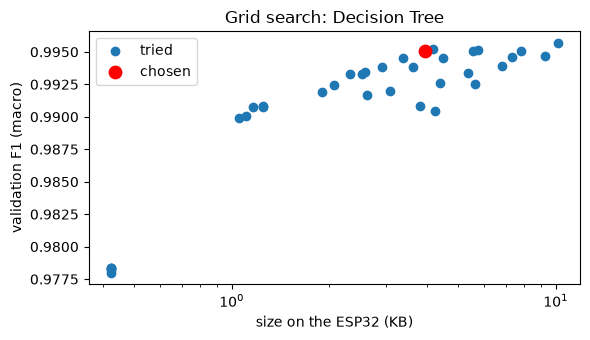

best val F1 0.9957 -> chosen {'max_depth': 10, 'min_samples_leaf': 2} (val F1 0.9951, 4.0 KB)
all tries saved to results/tuning/decision_tree.csv


In [247]:
# Grid search: Decision Tree
# max_depth        : max. number of questions from the top to a leaf (None = no limit)
# min_samples_leaf : a leaf must contain at least this many training rows
dt_grid = {
    "max_depth":        [4, 6, 8, 10, 12, 15, None],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    # "min_samples_split": [2, 10, 50],         # min. rows needed to split a node
    # "max_leaf_nodes":    [16, 32, 64, None],  # max. number of leaves (caps the size directly)
    # "criterion":         ["gini", "entropy"], # how a split is judged
    # "ccp_alpha":         [0.0, 1e-4, 1e-3],   # pruning: removes weak branches
    # "class_weight":      ["balanced", None],  # first remove class_weight="balanced" in BOTH places
}

def dt_train_and_score(params):
    model = DecisionTreeClassifier(**params, class_weight="balanced", random_state=SEED)
    model.fit(X_train, y_train)
    size = model.tree_.node_count * (2 + 4 + 2 + 2 + 4)   # feature, threshold, left, right, prob
    return val_score(model.predict(X_val)), size

dt_params = grid_search("Decision Tree", dt_grid, dt_train_and_score)

Decision Tree: accuracy=0.9965  precision=0.9973  recall=0.9981  F1=0.9977  size=4.0 KB


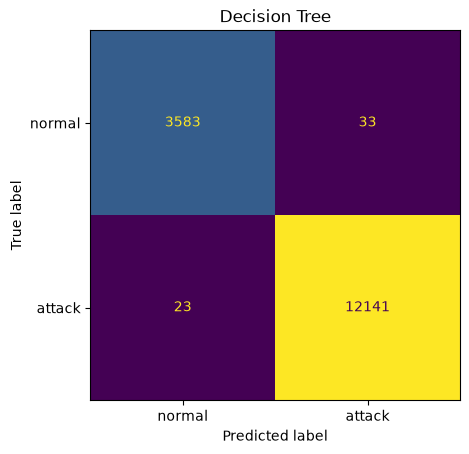

  -> exported to esp32/01_decision_tree


In [248]:
start = time.perf_counter()
dt = DecisionTreeClassifier(**dt_params,                 # max_depth + min_samples_leaf from the grid search
                            class_weight="balanced", random_state=SEED)

dt.fit(X_train, y_train)
dt_time = time.perf_counter() - start

y_pred = dt.predict(X_test)

tree = dt.tree_
feature = tree.feature.copy()
feature[feature < 0] = -1
threshold = tree.threshold
is_leaf = feature == -1

counts = tree.value[:, 0, :]
proba = counts / counts.sum(axis=1, keepdims=True)
leaf_class = proba.argmax(axis=1)
leaf_prob = np.where(is_leaf, proba.max(axis=1), 0.0)

left  = np.where(is_leaf, leaf_class, tree.children_left)
right = np.where(is_leaf, 0, tree.children_right)

index_type = c_int_type(len(feature))             # int16_t if the tree is small enough

dt_h  = f"#define DT_N_NODES {len(feature)}\n\n"
dt_h += c_array("DT_FEATURE",   feature,   "int16_t", per_line=20)
dt_h += c_array("DT_THRESHOLD", threshold, "float")
dt_h += c_array("DT_LEFT",      left,      index_type, per_line=20)
dt_h += c_array("DT_RIGHT",     right,     index_type, per_line=20)
dt_h += c_array("DT_LEAF_PROB", leaf_prob, "float")

index_bytes = 2 if index_type == "int16_t" else 4
dt_size = len(feature) * (2 + 4 + index_bytes + index_bytes + 4)   # feature, threshold, left, right, prob

evaluate("Decision Tree", y_test, y_pred, dt_time, dt.predict, dt_size, extra={"n_nodes": tree.node_count, "depth": dt.get_depth()})
plot_confusion_matrix("Decision Tree")

export_project("01_decision_tree", "DecisionTree", dt_h, y_pred)

### 5.2 Random Forest

Grid search Random Forest: 16 combinations
  {'n_estimators': 5, 'max_depth': 6}  ->  val F1 0.9871   5.2 KB   (0.1s)
  {'n_estimators': 5, 'max_depth': 10}  ->  val F1 0.9926   15.7 KB   (0.1s)
  {'n_estimators': 5, 'max_depth': 14}  ->  val F1 0.9935   21.9 KB   (0.1s)
  {'n_estimators': 5, 'max_depth': 18}  ->  val F1 0.9935   24.9 KB   (0.1s)
  {'n_estimators': 10, 'max_depth': 6}  ->  val F1 0.9888   11.4 KB   (0.1s)
  {'n_estimators': 10, 'max_depth': 10}  ->  val F1 0.9932   34.1 KB   (0.1s)
  {'n_estimators': 10, 'max_depth': 14}  ->  val F1 0.9940   47.7 KB   (0.1s)
  {'n_estimators': 10, 'max_depth': 18}  ->  val F1 0.9938   52.9 KB   (0.1s)
  {'n_estimators': 20, 'max_depth': 6}  ->  val F1 0.9897   22.4 KB   (0.1s)
  {'n_estimators': 20, 'max_depth': 10}  ->  val F1 0.9931   67.4 KB   (0.1s)
  {'n_estimators': 20, 'max_depth': 14}  ->  val F1 0.9940   98.3 KB   (0.1s)
  {'n_estimators': 20, 'max_depth': 18}  ->  val F1 0.9947   109.6 KB   (0.1s)
  {'n_estimators': 30, 'max_

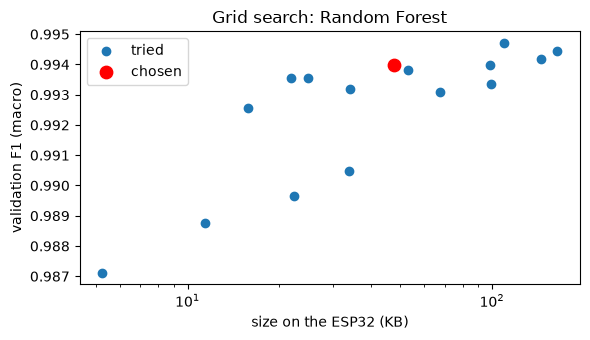

best val F1 0.9947 -> chosen {'n_estimators': 10, 'max_depth': 14} (val F1 0.9940, 47.7 KB)
all tries saved to results/tuning/random_forest.csv


In [249]:
# Grid search: Random Forest
# n_estimators : number of trees
# max_depth    : max. depth of every tree
rf_grid = {
    "n_estimators": [5, 10, 20, 30],
    "max_depth":    [6, 10, 14, 18],
    # "max_features": ["sqrt", 0.5, None],      # features each split may look at
    # "max_samples":  [0.5, 0.8, None],         # share of the rows each tree sees
    # "criterion":    ["gini", "entropy"],
    # "min_samples_leaf": [1, 5, 20],           # first remove min_samples_leaf=5 in BOTH places
    # "class_weight": ["balanced", "balanced_subsample", None],  # first remove class_weight="balanced" in BOTH places
}

def rf_train_and_score(params):
    model = RandomForestClassifier(**params, min_samples_leaf=5, class_weight="balanced",
                                   n_jobs=-1, random_state=SEED)
    model.fit(X_train, y_train)
    n_nodes  = sum(t.tree_.node_count for t in model.estimators_)
    n_leaves = sum(t.tree_.n_leaves for t in model.estimators_)
    size = n_nodes * (2 + 4 + 2 + 2) + n_leaves * 2 * 4 + len(model.estimators_) * 4
    return val_score(model.predict(X_val)), size

rf_params = grid_search("Random Forest", rf_grid, rf_train_and_score)

Random Forest: accuracy=0.9963  precision=0.9973  recall=0.9979  F1=0.9976  size=47.7 KB


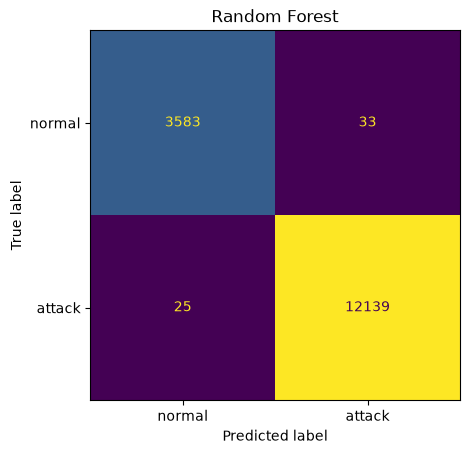

  -> exported to esp32/02_random_forest


In [250]:
start = time.perf_counter()
rf = RandomForestClassifier(**rf_params,             # n_estimators + max_depth from the grid search
                            min_samples_leaf=5,
                            class_weight="balanced",
                            n_jobs=-1,
                            random_state=SEED)
rf.fit(X_train, y_train)
rf_time = time.perf_counter() - start

y_pred = rf.predict(X_test)


all_feature, all_threshold, all_left, all_right, all_leaf_proba, roots = [], [], [], [], [], []
node_offset = 0      # how many nodes are already in the arrays (from earlier trees)
leaf_offset = 0      # how many leaves are already in leaf_proba

for single_tree in rf.estimators_:
    tree = single_tree.tree_
    feature = tree.feature.copy()
    feature[feature < 0] = -1
    is_leaf = feature == -1

    counts = tree.value[:, 0, :]
    proba  = counts / counts.sum(axis=1, keepdims=True)

    leaf_number = np.cumsum(is_leaf) - 1 + leaf_offset

    left  = np.where(is_leaf, leaf_number, tree.children_left + node_offset)
    right = np.where(is_leaf, 0,           tree.children_right + node_offset)

    roots.append(node_offset)
    all_feature.append(feature)
    all_threshold.append(tree.threshold)
    all_left.append(left)
    all_right.append(right)
    all_leaf_proba.append(proba[is_leaf])

    node_offset += len(feature)
    leaf_offset += is_leaf.sum()

feature    = np.concatenate(all_feature)
threshold  = np.concatenate(all_threshold)
left       = np.concatenate(all_left)
right      = np.concatenate(all_right)
leaf_proba = np.concatenate(all_leaf_proba)

index_type = c_int_type(max(len(feature), leaf_offset))

rf_h  = f"#define RF_N_TREES {len(rf.estimators_)}\n"
rf_h += f"#define RF_N_NODES {len(feature)}\n"
rf_h += f"#define RF_N_LEAVES {leaf_offset}\n\n"
rf_h += c_array("RF_ROOT",       roots,      "int32_t", per_line=20)
rf_h += c_array("RF_FEATURE",    feature,    "int16_t", per_line=20)
rf_h += c_array("RF_THRESHOLD",  threshold,  "float")
rf_h += c_array("RF_LEFT",       left,       index_type, per_line=20)
rf_h += c_array("RF_RIGHT",      right,      index_type, per_line=20)
rf_h += c_array("RF_LEAF_PROBA", leaf_proba, "float")

index_bytes = 2 if index_type == "int16_t" else 4
rf_size = (len(feature) * (2 + 4 + index_bytes + index_bytes)
           + leaf_proba.size * 4 
           + len(roots) * 4)

evaluate("Random Forest", y_test, y_pred, rf_time, rf.predict, rf_size,
         extra={"n_nodes": len(feature)})
plot_confusion_matrix("Random Forest")

# 4) Write the files into esp32/02_random_forest
export_project("02_random_forest", "RandomForest", rf_h, y_pred)

## 5.2b XGboost

Grid search XGBoost: 60 combinations
  {'n_estimators': 25, 'max_depth': 3, 'learning_rate': 0.1}  ->  val F1 0.9804   3.8 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 3, 'learning_rate': 0.3}  ->  val F1 0.9914   3.6 KB   (0.1s)
  {'n_estimators': 25, 'max_depth': 3, 'learning_rate': 0.5}  ->  val F1 0.9925   3.6 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 3, 'learning_rate': 0.7}  ->  val F1 0.9917   3.5 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 4, 'learning_rate': 0.1}  ->  val F1 0.9913   7.5 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 4, 'learning_rate': 0.3}  ->  val F1 0.9932   7.0 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 4, 'learning_rate': 0.5}  ->  val F1 0.9941   6.4 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 4, 'learning_rate': 0.7}  ->  val F1 0.9946   6.2 KB   (0.2s)
  {'n_estimators': 25, 'max_depth': 6, 'learning_rate': 0.1}  ->  val F1 0.9933   20.0 KB   (0.3s)
  {'n_estimators': 25, 'max_depth': 6, 'learning_rate': 0.3}  ->  val F1 0.9946 

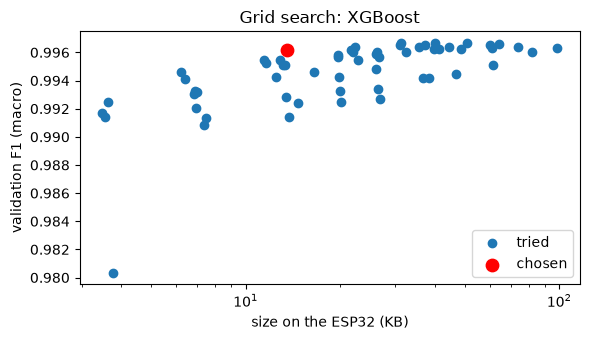

best val F1 0.9967 -> chosen {'n_estimators': 25, 'max_depth': 6, 'learning_rate': 0.5} (val F1 0.9962, 13.5 KB)
all tries saved to results/tuning/xgboost.csv


In [251]:
xgb_grid = {
    "n_estimators":  [25, 50, 100, 150, 200],
    "max_depth":     [3, 4, 6],
    "learning_rate": [0.1, 0.3, 0.5, 0.7],
    # "min_child_weight": [1, 5, 10],   # like min_samples_leaf: larger = smaller trees
    # "gamma":            [0, 0.5, 1],  # min. gain needed to split: larger = smaller trees
    # "subsample":        [0.7, 1.0],   # share of rows per tree
    # "colsample_bytree": [0.7, 1.0],   # share of features per tree
    # "reg_lambda":       [0, 1, 5],    # penalty on large leaf values
    # "reg_alpha":        [0, 1],
}

def xgb_train_and_score(params):
    model = XGBClassifier(**params,
                          scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                          tree_method="exact", random_state=SEED)
    model.fit(X_train, y_train)
    n_nodes = len(model.get_booster().trees_to_dataframe())
    size = n_nodes * (2 + 4 + 2 + 2) + params["n_estimators"] * 4 + 4
    return val_score(model.predict(X_val)), size

xgb_params = grid_search("XGBoost", xgb_grid, xgb_train_and_score)

XGBoost: accuracy=0.9972  precision=0.9987  recall=0.9977  F1=0.9982  size=13.5 KB


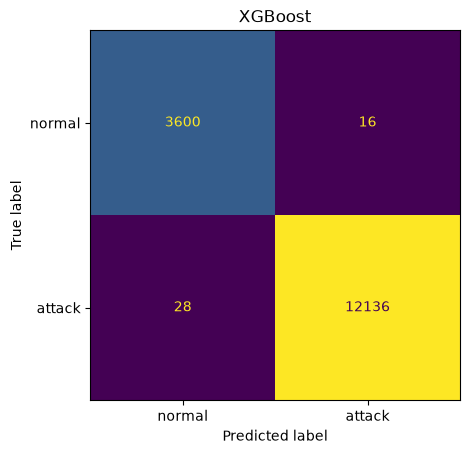

  -> exported to esp32/02b_xgboost


In [252]:
# 1) Train
start = time.perf_counter()
xgb = XGBClassifier(**xgb_params,             # n_estimators, max_depth, learning_rate from the grid search
                    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),  # = class_weight "balanced"
                    tree_method="exact",      # split points halfway between two values (see note below)
                    random_state=SEED)
xgb.fit(X_train, y_train)
xgb_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = xgb.predict(X_test)

# 3) Put all trees into flat arrays (same idea as the random forest)
#    feature   : which feature a node checks (-1 = leaf)
#    threshold : go LEFT if x[feature] < threshold   (XGBoost uses "<", not "<=")
#                for a leaf: the leaf value that is added to the score
#    left/right: index of the next node
#    Note: the default tree_method ("hist") puts split points exactly ON data values.
#    The ESP32 computes log1p/z-score in float32, so a value can come out a tiny bit
#    different and land on the wrong side (7% of samples disagreed in testing).
#    "exact" puts each split halfway between two values -> 100% agreement.
trees = xgb.get_booster().trees_to_dataframe()   # one row per node of every tree

all_feature, all_threshold, all_left, all_right, roots = [], [], [], [], []
offset = 0
for tree_id, nodes in trees.groupby("Tree"):
    nodes = nodes.reset_index(drop=True)
    position = {node_id: offset + i for i, node_id in enumerate(nodes["ID"])}   # "3-5" -> index
    roots.append(offset)
    for _, node in nodes.iterrows():
        if node["Feature"] == "Leaf":
            all_feature.append(-1)
            all_threshold.append(node["Gain"])            # for leaves, "Gain" is the leaf value
            all_left.append(0)
            all_right.append(0)
        else:
            all_feature.append(int(node["Feature"][1:]))   # "f7" -> 7
            all_threshold.append(node["Split"])
            all_left.append(position[node["Yes"]])
            all_right.append(position[node["No"]])
    offset += len(nodes)

# the starting value ("base score"): total score from XGBoost minus the sum of the leaves
def leaf_sum(x):
    total = 0.0
    for root in roots:
        n = root
        while all_feature[n] >= 0:
            n = all_left[n] if x[all_feature[n]] < all_threshold[n] else all_right[n]
        total += all_threshold[n]
    return total

margins = xgb.predict(X_train[:50], output_margin=True)   # score before the sigmoid
base_score = float(np.mean([m - leaf_sum(x) for m, x in zip(margins, X_train[:50])]))

index_type = c_int_type(len(all_feature))
xgb_h  = f"#define XGB_N_TREES {len(roots)}\n"
xgb_h += f"#define XGB_N_NODES {len(all_feature)}\n"
xgb_h += f"static const float XGB_BASE_SCORE = {c_float(base_score)};\n\n"
xgb_h += c_array("XGB_ROOT",      roots,         "int32_t", per_line=20)
xgb_h += c_array("XGB_FEATURE",   all_feature,   "int16_t", per_line=20)
xgb_h += c_array("XGB_THRESHOLD", all_threshold, "float")
xgb_h += c_array("XGB_LEFT",      all_left,      index_type, per_line=20)
xgb_h += c_array("XGB_RIGHT",     all_right,     index_type, per_line=20)

index_bytes = 2 if index_type == "int16_t" else 4
xgb_size = len(all_feature) * (2 + 4 + index_bytes + index_bytes) + len(roots) * 4 + 4

evaluate("XGBoost", y_test, y_pred, xgb_time, xgb.predict, xgb_size,
         extra={"n_nodes": len(all_feature)})
plot_confusion_matrix("XGBoost")

# 4) Write the files into esp32/02b_xgboost
export_project("02b_xgboost", "XGBoost", xgb_h, y_pred)

### 5.3 Logistic Regression 

Grid search Logistic Regression: 18 combinations
  {'C': 0.01, 'l1_ratio': 0, 'solver': 'saga'}  ->  val F1 0.9690   0.1 KB   (0.4s)
  {'C': 0.01, 'l1_ratio': 0.5, 'solver': 'saga'}  ->  val F1 0.9689   0.1 KB   (0.4s)
  {'C': 0.01, 'l1_ratio': 1, 'solver': 'saga'}  ->  val F1 0.9691   0.1 KB   (0.4s)
  {'C': 0.1, 'l1_ratio': 0, 'solver': 'saga'}  ->  val F1 0.9697   0.1 KB   (1.3s)
  {'C': 0.1, 'l1_ratio': 0.5, 'solver': 'saga'}  ->  val F1 0.9698   0.1 KB   (2.1s)
  {'C': 0.1, 'l1_ratio': 1, 'solver': 'saga'}  ->  val F1 0.9697   0.1 KB   (0.6s)
  {'C': 1, 'l1_ratio': 0, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (1.8s)
  {'C': 1, 'l1_ratio': 0.5, 'solver': 'saga'}  ->  val F1 0.9698   0.1 KB   (2.0s)
  {'C': 1, 'l1_ratio': 1, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (2.1s)
  {'C': 10, 'l1_ratio': 0, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (1.6s)
  {'C': 10, 'l1_ratio': 0.5, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (2.0s)
  {'C': 10, 'l1_ratio': 1, 'solver'

/home/berat/Documents/Master/Models_tuning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1399: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(


  {'C': inf, 'l1_ratio': 0.5, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (1.9s)
  {'C': inf, 'l1_ratio': 1, 'solver': 'saga'}  ->  val F1 0.9699   0.1 KB   (1.8s)


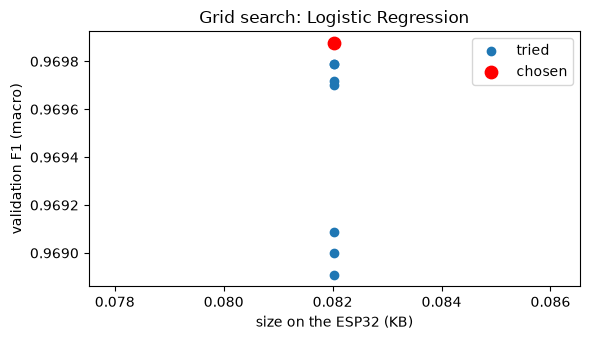

best val F1 0.9699 -> chosen {'C': 1, 'l1_ratio': 0, 'solver': 'saga'} (val F1 0.9699, 0.1 KB)
all tries saved to results/tuning/logistic_regression.csv


In [253]:
# Grid search: Logistic Regression
# C : how strongly mistakes are punished (small C = simpler model, large C = fits the data closer)
# (the size is always 84 bytes, so the best score decides)
lr_grid = {
    "C":        [0.01, 0.1, 1, 10, 100, np.inf],   # np.inf = no penalty at all ("none")
    "l1_ratio": [0, 0.5, 1],                        # 0 = L2, 1 = L1, 0.5 = elastic net (mix)
    "solver":   ["saga"],                           # the solver that can do all of them
    # "class_weight": ["balanced", None],   # first remove class_weight="balanced" in BOTH places
}

def lr_train_and_score(params):
    model = LogisticRegression(**params, max_iter=2000, class_weight="balanced")
    model.fit(X_train, y_train)
    return val_score(model.predict(X_val)), (N_FEATURES + 1) * 4

lr_params = grid_search("Logistic Regression", lr_grid, lr_train_and_score)

Logistic Regression: accuracy=0.9759  precision=0.9884  recall=0.9802  F1=0.9843  size=0.1 KB


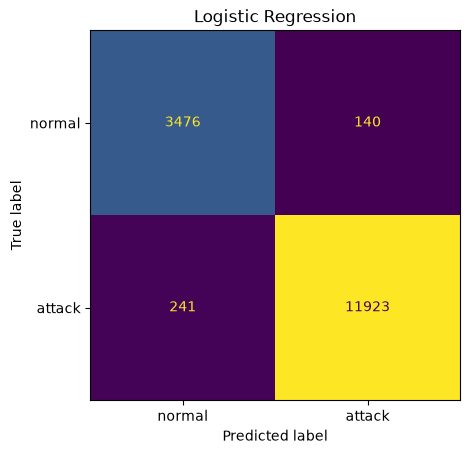

  -> exported to esp32/03_logistic_regression


In [254]:
start = time.perf_counter()
lr = LogisticRegression(**lr_params, max_iter=2000, class_weight="balanced")
lr.fit(X_train, y_train)
lr_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = lr.predict(X_test)

# 3) Write the weights as C arrays
weights = lr.coef_[0]          # 20 numbers, one per feature
bias    = lr.intercept_        # 1 number

lr_h  = "#define LIN_N_OUT 1\n"     # one output z (binary task)
lr_h += "#define LIN_PROBA 1\n\n"   # 1 = also compute the probability (sigmoid)
lr_h += c_array("LIN_W", weights, "float")
lr_h += c_array("LIN_B", bias, "float")

lr_size = (len(weights) + len(bias)) * 4           # 4 bytes per float

evaluate("Logistic Regression", y_test, y_pred, lr_time, lr.predict, lr_size)
plot_confusion_matrix("Logistic Regression")

# 4) Write the files into esp32/03_logistic_regression
export_project("03_logistic_regression", "LogisticRegression", lr_h, y_pred)

### 5.4 Linear SVM

Grid search Linear SVM: 4 combinations
  {'C': 0.01}  ->  val F1 0.9693   0.1 KB   (0.3s)
  {'C': 0.1}  ->  val F1 0.9692   0.1 KB   (0.4s)
  {'C': 1}  ->  val F1 0.9686   0.1 KB   (0.5s)
  {'C': 10}  ->  val F1 0.9686   0.1 KB   (0.5s)


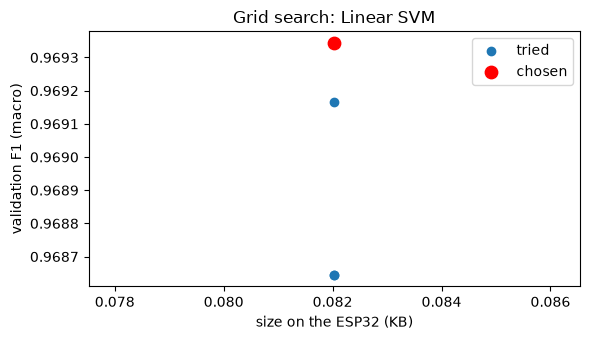

best val F1 0.9693 -> chosen {'C': 0.01} (val F1 0.9693, 0.1 KB)
all tries saved to results/tuning/linear_svm.csv


In [255]:
svm_grid = {
    "C": [0.01, 0.1, 1, 10], # C : how strongly mistakes are punished
    # switch on only ONE of these two ("l1" does not work together with "hinge"):
    # "loss":    ["hinge", "squared_hinge"],
    # "penalty": ["l1", "l2"],              # "l1" sets the weights of useless features to 0
}

def svm_train_and_score(params):
    model = LinearSVC(**params, class_weight="balanced", max_iter=5000, random_state=SEED)
    model.fit(X_train, y_train)
    return val_score(model.predict(X_val)), (N_FEATURES + 1) * 4

svm_params = grid_search("Linear SVM", svm_grid, svm_train_and_score)

Linear SVM: accuracy=0.9758  precision=0.9882  recall=0.9803  F1=0.9842  size=0.1 KB


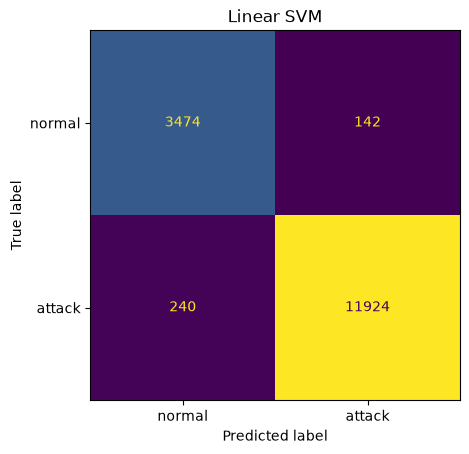

  -> exported to esp32/04_svm


In [256]:
start = time.perf_counter()
svm = LinearSVC(**svm_params,           # C from the grid search
                class_weight="balanced",
                max_iter=5000,
                random_state=SEED)
svm.fit(X_train, y_train)
svm_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = svm.predict(X_test)

# 3) Write the weights as C arrays
weights = svm.coef_[0]
bias    = svm.intercept_

svm_h  = "#define LIN_N_OUT 1\n"
svm_h += "#define LIN_PROBA 0\n\n"      # 0 = an SVM gives no probability, only z
svm_h += c_array("LIN_W", weights, "float")
svm_h += c_array("LIN_B", bias, "float")

svm_size = (len(weights) + len(bias)) * 4

evaluate("Linear SVM", y_test, y_pred, svm_time, svm.predict, svm_size)
plot_confusion_matrix("Linear SVM")

# 4) Write the files into esp32/04_svm
export_project("04_svm", "LinearSVM", svm_h, y_pred)

### 5.4b Kernel SVM

Grid search RBF SVM: 6 combinations
  {'C': 0.1, 'gamma': 'scale'}  ->  val F1 0.9837   81.8 KB   (0.6s)
  {'C': 0.1, 'gamma': 0.1}  ->  val F1 0.9834   73.6 KB   (0.5s)
  {'C': 1, 'gamma': 'scale'}  ->  val F1 0.9811   37.2 KB   (0.3s)
  {'C': 1, 'gamma': 0.1}  ->  val F1 0.9855   35.3 KB   (0.3s)
  {'C': 10, 'gamma': 'scale'}  ->  val F1 0.9902   23.1 KB   (0.2s)
  {'C': 10, 'gamma': 0.1}  ->  val F1 0.9900   22.1 KB   (0.2s)


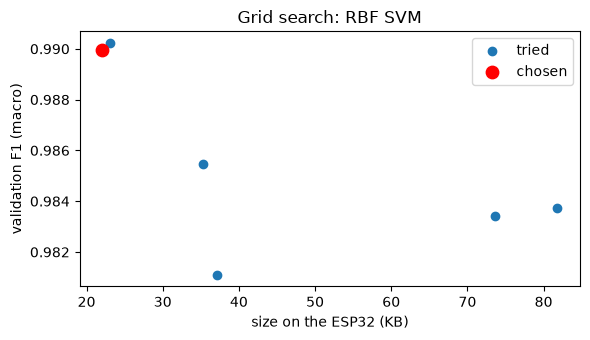

best val F1 0.9902 -> chosen {'C': 10, 'gamma': 0.1} (val F1 0.9900, 22.1 KB)
all tries saved to results/tuning/rbf_svm.csv


In [282]:
# Grid search: RBF (kernel) SVM
# More support vectors = bigger AND slower on the ESP32 (one kernel calculation per SV).
N_SVM_TRAIN = 10000    # kernel SVMs train slowly (time grows ~ n^2)
svm_rows, _ = train_test_split(np.arange(len(X_train)), train_size=N_SVM_TRAIN,
                               stratify=y_train, random_state=SEED)

rbf_grid = {
    "C":     [0.1, 1, 10], # C     : how strongly mistakes are punished
    "gamma": ["scale", 0.1], # gamma : width of the "bumps" ("scale" = chosen from the data, larger = narrower)
    # "class_weight": ["balanced", None],
}

def rbf_train_and_score(params):
    model = SVC(kernel="rbf", **params, class_weight="balanced")
    model.fit(X_train[svm_rows], y_train[svm_rows])
    n_sv = len(model.support_vectors_)
    size = (n_sv * N_FEATURES + n_sv + 2) * 4
    return val_score(model.predict(X_val)), size

rbf_params = grid_search("RBF SVM", rbf_grid, rbf_train_and_score)

RBF SVM: accuracy=0.9925  precision=0.9943  recall=0.9959  F1=0.9951  size=22.1 KB


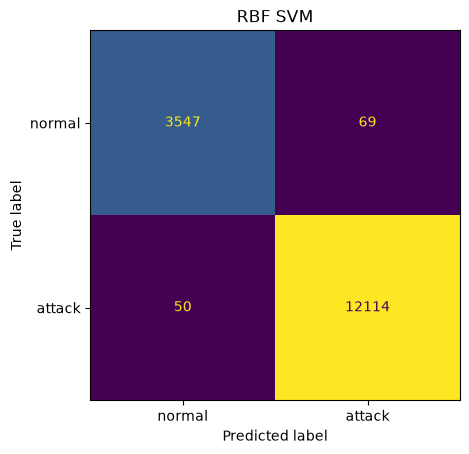

269 support vectors -> 22.1 KB on the ESP32 and 269 kernel calculations per prediction (linear SVM: 84 bytes, 20 multiply-adds)
  -> exported to esp32/04b_svm_rbf


In [283]:
# 1) Train on the stratified sample of the training data (svm_rows, made in the tuning cell)
start = time.perf_counter()
rbf = SVC(kernel="rbf",
          **rbf_params,             # C and gamma from the grid search
          class_weight="balanced")
rbf.fit(X_train[svm_rows], y_train[svm_rows])
rbf_time = time.perf_counter() - start

# 2) Evaluate on the full test set
y_pred = rbf.predict(X_test)

# 3) Write the model as C arrays
support_vectors = rbf.support_vectors_       # (number of SVs) x 20 features
alphas          = rbf.dual_coef_[0]          # one weight per support vector
bias            = rbf.intercept_[0]
gamma           = rbf._gamma                 # the actual number behind gamma="scale"
n_sv            = len(support_vectors)

rbf_h  = f"#define SVM_N_SV {n_sv}\n"
rbf_h += f"static const float SVM_GAMMA = {c_float(gamma)};\n"
rbf_h += f"static const float SVM_B = {c_float(bias)};\n\n"
rbf_h += c_array("SVM_ALPHA", alphas, "float")
rbf_h += c_array("SVM_SV", support_vectors, "float")

rbf_size = (n_sv * N_FEATURES + n_sv + 2) * 4     # support vectors + alphas + gamma + bias

evaluate("RBF SVM", y_test, y_pred, rbf_time, rbf.predict, rbf_size,
         extra={"n_support_vectors": n_sv})
plot_confusion_matrix("RBF SVM")
print(f"{n_sv} support vectors -> {rbf_size/1024:.1f} KB on the ESP32 and {n_sv} "
      f"kernel calculations per prediction (linear SVM: 84 bytes, 20 multiply-adds)")

# 4) Write the files into esp32/04b_svm_rbf
export_project("04b_svm_rbf", "RBF_SVM", rbf_h, y_pred)

### 5.5 Gaussian Naive Bayes

Grid search Naive Bayes: 3 combinations
  {'var_smoothing': 1e-09}  ->  val F1 0.8453   0.3 KB   (0.0s)
  {'var_smoothing': 1e-06}  ->  val F1 0.8453   0.3 KB   (0.0s)
  {'var_smoothing': 0.001}  ->  val F1 0.8458   0.3 KB   (0.0s)


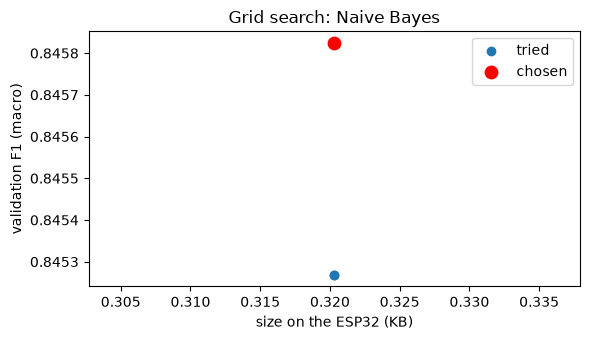

best val F1 0.8458 -> chosen {'var_smoothing': 0.001} (val F1 0.8458, 0.3 KB)
all tries saved to results/tuning/naive_bayes.csv


In [259]:
# Grid search: Gaussian Naive Bayes
# var_smoothing : a small number added to every variance (stops tiny variances
#                 from making the model over-confident). Default 1e-9.
# (the size is always the same, so the best score decides)
nb_grid = {
    "var_smoothing": [1e-9, 1e-6, 1e-3],
    # "priors": [None, [0.5, 0.5]],
}

def nb_train_and_score(params):
    model = GaussianNB(**params)
    model.fit(X_train, y_train)
    return val_score(model.predict(X_val)), (2 * N_FEATURES * 2 + 2) * 4

nb_params = grid_search("Naive Bayes", nb_grid, nb_train_and_score)

Naive Bayes: accuracy=0.8795  precision=0.9402  recall=0.9010  F1=0.9202  size=0.3 KB


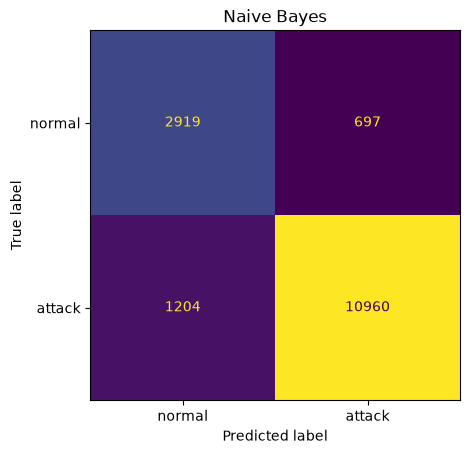

  -> exported to esp32/05_naive_bayes


In [260]:
start = time.perf_counter()
nb = GaussianNB(**nb_params)          # var_smoothing from the grid search
nb.fit(X_train, y_train)
nb_time = time.perf_counter() - start

# 2) Evaluate on the test set
y_pred = nb.predict(X_test)

# 3) Write the parameters as C arrays
mean     = nb.theta_          # shape (2 classes, 20 features)
variance = nb.var_            # shape (2 classes, 20 features)
prior    = nb.class_prior_    # how common each class is in the training data

# Score of a class on the ESP32:
#   score = const - 0.5 * sum( (x - mean)^2 / variance )
# The part that does not depend on x is calculated here once:
#   const = log(prior) - 0.5 * sum( log(2 * pi * variance) )
nb_const = np.log(prior) - 0.5 * np.sum(np.log(2.0 * np.pi * variance), axis=1)

nb_h  = c_array("NB_THETA",   mean,           "float")   # means
nb_h += c_array("NB_INV_VAR", 1.0 / variance, "float")   # 1/variance (multiply is faster than divide)
nb_h += c_array("NB_CONST",   nb_const,       "float")

nb_size = (mean.size + variance.size + len(nb_const)) * 4

evaluate("Naive Bayes", y_test, y_pred, nb_time, nb.predict, nb_size)
plot_confusion_matrix("Naive Bayes")

# 4) Write the files into esp32/05_naive_bayes
export_project("05_naive_bayes", "GaussianNB", nb_h, y_pred)

### 5.6 K-Means anomaly detector (unsupervised)

Grid search K-Means: 96 combinations
  {'n_clusters': 8, 'percentile': 74, 'n_init': 5, 'init': 'k-means++'}  ->  val F1 0.8651   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 74, 'n_init': 5, 'init': 'random'}  ->  val F1 0.8939   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 74, 'n_init': 10, 'init': 'k-means++'}  ->  val F1 0.8651   0.6 KB   (0.1s)
  {'n_clusters': 8, 'percentile': 74, 'n_init': 10, 'init': 'random'}  ->  val F1 0.8607   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 80, 'n_init': 5, 'init': 'k-means++'}  ->  val F1 0.8682   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 80, 'n_init': 5, 'init': 'random'}  ->  val F1 0.8922   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 80, 'n_init': 10, 'init': 'k-means++'}  ->  val F1 0.8682   0.6 KB   (0.1s)
  {'n_clusters': 8, 'percentile': 80, 'n_init': 10, 'init': 'random'}  ->  val F1 0.8724   0.6 KB   (0.0s)
  {'n_clusters': 8, 'percentile': 85, 'n_init': 5, 'init': 'k-means++'}  ->  val F1 0.8375   0.6 KB

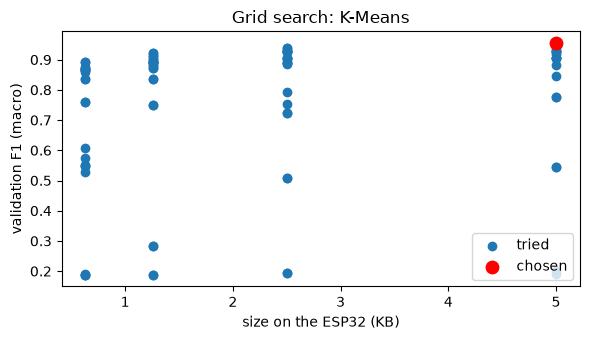

best val F1 0.9554 -> chosen {'n_clusters': 64, 'percentile': 90, 'n_init': 5, 'init': 'k-means++'} (val F1 0.9554, 5.0 KB)
all tries saved to results/tuning/kmeans.csv


In [261]:
km_grid = {
    "n_clusters": [8, 16, 32, 64], 
    "percentile": [74, 80, 85, 90, 95, 99],
    "n_init":     [5, 10],
    "init":       ["k-means++", "random"],
}

def km_train_and_score(params):
    model = KMeans(n_clusters=params["n_clusters"],
                   n_init=params.get("n_init", 5),            # 5 if not in the grid
                   init=params.get("init", "k-means++"),
                   random_state=SEED)
    model.fit(X_train[y_train == 0])
    val_scores = (model.transform(X_val) ** 2).min(axis=1)
    threshold = np.percentile(val_scores[y_val == 0], params["percentile"])
    size = (params["n_clusters"] * N_FEATURES + 1) * 4
    return val_score((val_scores > threshold).astype(int)), size

km_params = grid_search("K-Means", km_grid, km_train_and_score)

K-Means (anomaly): accuracy=0.9642  precision=0.9659  recall=0.9884  F1=0.9770  size=5.0 KB
ROC-AUC = 0.968


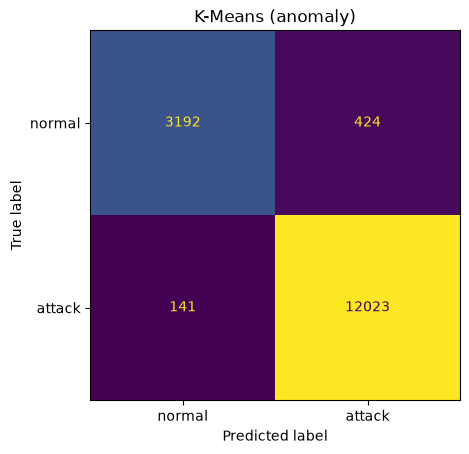

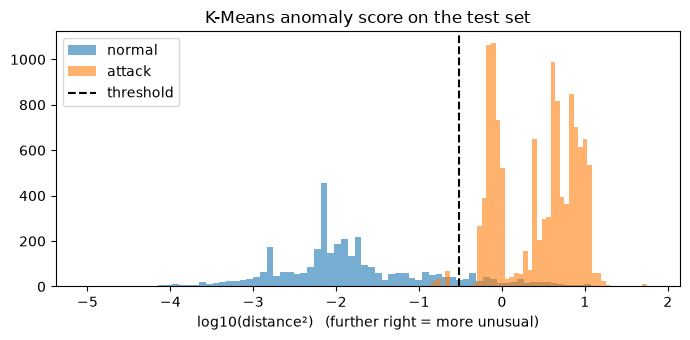

  -> exported to esp32/06_kmeans


In [262]:
K = km_params["n_clusters"]               # number of clusters (from the grid search)
KM_PERCENTILE = km_params["percentile"]   # threshold percentile (from the grid search)

# 1) Train on normal traffic only (label 0)
start = time.perf_counter()
km = KMeans(n_clusters=K, n_init=km_params.get("n_init", 5), init=km_params.get("init", "k-means++"), random_state=SEED)
km.fit(X_train[y_train == 0])
km_time = time.perf_counter() - start


def km_score(X):
    """Anomaly score = squared distance to the nearest cluster centre."""
    distances = km.transform(X)              # distance to every centre, shape (rows, K)
    return (distances ** 2).min(axis=1)      # keep the nearest one


def km_predict(X):
    """1 (attack) if the score is above the threshold, else 0 (normal)."""
    return (km_score(X) > km_threshold).astype(int)


# 2) Choose the threshold with NORMAL validation data
#    e.g. 95th percentile -> 95% of normal traffic stays below it (~5% false alarms)
normal_val_scores = km_score(X_val[y_val == 0])
km_threshold = float(np.percentile(normal_val_scores, KM_PERCENTILE))

# 3) Evaluate on the test set
y_pred   = km_predict(X_test)
test_scores = km_score(X_test)
km_auc   = roc_auc_score(y_test, test_scores)   # how well the score separates the classes (1.0 = perfect)

# 4) Write the model as C arrays: the K centres + the threshold
km_h  = f"#define KM_K {K}\n"
km_h += f"static const float KM_THRESHOLD = {c_float(km_threshold)};\n\n"
km_h += c_array("KM_CENTROIDS", km.cluster_centers_, "float")

km_size = (km.cluster_centers_.size + 1) * 4      # K x 20 centres + 1 threshold

evaluate("K-Means (anomaly)", y_test, y_pred, km_time, km_predict, km_size,
         extra={"threshold": km_threshold, "roc_auc": km_auc})
print(f"ROC-AUC = {km_auc:.3f}")
plot_confusion_matrix("K-Means (anomaly)")

# 5) Plot: how the anomaly scores of normal vs attack traffic look
plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(test_scores[y_test == 0] + 1e-6), bins=80, alpha=0.6, label="normal")
plt.hist(np.log10(test_scores[y_test == 1] + 1e-6), bins=80, alpha=0.6, label="attack")
plt.axvline(np.log10(km_threshold), color="k", linestyle="--", label="threshold")
plt.xlabel("log10(distance²)   (further right = more unusual)")
plt.title("K-Means anomaly score on the test set")
plt.legend()
plt.tight_layout()
plt.show()

# 6) Write the files into esp32/06_kmeans
export_project("06_kmeans", "KMeansAnomaly", km_h, y_pred)

## 6. Neural networks (TensorFlow/Keras → int8 TensorFlow Lite Micro)

In [263]:
# ---------------------------------------------------------------
# 6.0 Helpers for the neural networks
# ---------------------------------------------------------------
# The networks are trained in Keras (float32), then converted to int8
# TensorFlow Lite so they fit on the ESP32 and run with TFLite Micro.


# ---- 1) Training --------------------------------------------------------
def train_keras(model, X, y, X_val, y_val, loss, class_weight=None,
                learning_rate=1e-3, batch_size=NN_BATCH):
    """Train a Keras model and stop early when the validation loss stops improving."""
    metrics = [] if loss == "mse" else ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss=loss, metrics=metrics)

    stop_early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                               restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X, y, validation_data=(X_val, y_val),
                        epochs=NN_EPOCHS, batch_size=batch_size,
                        class_weight=class_weight, callbacks=[stop_early], verbose=0)
    train_time = time.perf_counter() - start

    epochs = len(history.history["loss"])
    print(f"trained {epochs} epochs in {train_time:.1f}s, "
          f"best val_loss = {min(history.history['val_loss']):.4f}")
    return history, train_time

TRAIN_SETTINGS = ["learning_rate", "batch_size"]

def split_params(params):
    """{'n_layers': 2, 'learning_rate': 0.003} -> ({'n_layers': 2}, {'learning_rate': 0.003})"""
    network  = {k: v for k, v in params.items() if k not in TRAIN_SETTINGS}
    training = {k: v for k, v in params.items() if k in TRAIN_SETTINGS}
    return network, training

def plot_history(history, title):
    """Plot the loss (and accuracy) per epoch for training and validation data."""
    has_accuracy = "accuracy" in history.history
    fig, axes = plt.subplots(1, 2 if has_accuracy else 1, figsize=(10, 3))
    axes = np.atleast_1d(axes)

    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - loss")
    axes[0].legend()

    if has_accuracy:
        axes[1].plot(history.history["accuracy"], label="train")
        axes[1].plot(history.history["val_accuracy"], label="validation")
        axes[1].set_title(f"{title} - accuracy")
        axes[1].legend()

    plt.tight_layout()
    plt.show()


# ---- 2) Convert to int8 TensorFlow Lite ---------------------------------
def to_int8_tflite(model, X_example):
    """Convert a trained Keras model to a fully int8-quantised .tflite model.

    The converter needs some example inputs (the "representative dataset")
    to find out the value range of every layer -> 300 training samples.
    """
    input_shape = tuple(model.input_shape[1:])                # e.g. (20,) or (20, 1)

    def representative_dataset():
        rows = np.random.RandomState(SEED).choice(len(X_example), 300, replace=False)
        for i in rows:
            yield [X_example[i].reshape((1,) + input_shape).astype(np.float32)]

    # rebuild the model with a fixed batch size of 1 (the ESP32 handles one sample
    # at a time) -> fixed shapes, so TFLite needs fewer and simpler operations
    inp = keras.Input(batch_shape=(1,) + input_shape)
    fixed_model = keras.Model(inp, model(inp))

    converter = tf.lite.TFLiteConverter.from_keras_model(fixed_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]  # int8 only
    converter.inference_input_type = tf.int8      # the ESP32 gives int8 input
    converter.inference_output_type = tf.int8     # and gets int8 output
    return converter.convert()                    # the .tflite file as bytes


# ---- 3) Run the int8 model in Python, the same way the ESP32 does -------
class TFLiteModel:
    """Runs an int8 .tflite model like main/model.cpp on the ESP32, so the
    accuracy we report is the accuracy of the model that really runs on the board."""

    def __init__(self, tflite_bytes):
        # BUILTIN_REF = the plain reference maths, closest to TFLite Micro
        self.interpreter = tf.lite.Interpreter(
            model_content=tflite_bytes,
            experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
        self.interpreter.allocate_tensors()
        self.input  = self.interpreter.get_input_details()[0]
        self.output = self.interpreter.get_output_details()[0]

        # int8 value = round(float / scale) + zero_point
        self.in_scale,  self.in_zero  = self.input["quantization"]
        self.out_scale, self.out_zero = self.output["quantization"]

        # which TFLite operations the model uses (needed for the ESP32 code)
        self.ops = sorted({op["op_name"] for op in self.interpreter._get_ops_details()})

    def to_int8(self, X):
        """float -> int8, rounding exactly like lroundf() in C."""
        v = X / self.in_scale
        rounded = np.sign(v) * np.floor(np.abs(v) + 0.5)
        return np.clip(rounded + self.in_zero, -128, 127).astype(np.int8)

    def raw_output(self, X):
        """Run the model on every row of X, return the int8 outputs."""
        X_int8 = self.to_int8(X)
        n_outputs = self.output["shape"][-1]
        outputs = np.empty((len(X), n_outputs), dtype=np.int8)
        for i in range(len(X)):                                   # one sample at a time
            self.interpreter.set_tensor(self.input["index"], X_int8[i].reshape(self.input["shape"]))
            self.interpreter.invoke()
            outputs[i] = self.interpreter.get_tensor(self.output["index"])[0]
        return outputs

    def to_float(self, out_int8):
        """int8 output -> float."""
        return (out_int8.astype(np.float32) - self.out_zero) * self.out_scale

    def predict(self, X):
        """Class with the highest output (for the classifiers)."""
        return self.raw_output(X).argmax(axis=1)


# ---- 4) Write model_data.h for TFLite Micro ------------------------------
# TFLite Micro only includes the operations you register (saves flash).
# This table translates the TFLite operation name to the C++ function.
TFLM_OPS = {
    "FULLY_CONNECTED": "AddFullyConnected",   # Dense layer
    "CONV_2D":         "AddConv2D",           # Conv1D becomes Conv2D in TFLite
    "MAX_POOL_2D":     "AddMaxPool2D",
    "MEAN":            "AddMean",             # GlobalAveragePooling
    "RESHAPE":         "AddReshape",
    "EXPAND_DIMS":     "AddExpandDims",
    "SQUEEZE":         "AddSqueeze",
    "SOFTMAX":         "AddSoftmax",
    "LOGISTIC":        "AddLogistic",         # sigmoid
    "RELU":            "AddRelu",
    "TANH":            "AddTanh",           # only needed for activation="tanh"
    "QUANTIZE":        "AddQuantize",
    "DEQUANTIZE":      "AddDequantize",
}


def tflm_model_h(tflite_bytes, tfl, arena_kb, extra=""):
    """C code for model_data.h: the .tflite bytes + which ops to register."""
    missing = [op for op in tfl.ops if op not in TFLM_OPS]
    if missing:
        raise ValueError(f"add these operations to TFLM_OPS: {missing}")

    register = " ".join(f"(r).{TFLM_OPS[op]}();" for op in tfl.ops)

    h  = f"// operations used by the model: {', '.join(tfl.ops)}\n"
    h += f"#define MODEL_OP_COUNT {len(tfl.ops)}\n"
    h += f"#define MODEL_REGISTER_OPS(r) do {{ {register} }} while (0)\n"
    h += "// working memory for TFLite Micro (the board prints how much is really used)\n"
    h += f"#define TENSOR_ARENA_SIZE ({arena_kb} * 1024)\n"
    h += extra + "\n"
    h += c_array("g_model", np.frombuffer(tflite_bytes, dtype=np.uint8), "unsigned char",
                 per_line=16, align=True)
    h += f"static const unsigned int g_model_len = {len(tflite_bytes)};\n"
    return h

### 6.1 MLP (multilayer perceptron)

Grid search MLP: 108 combinations
trained 30 epochs in 5.7s, best val_loss = 0.0286
  {'layers': (16,), 'dropout': 0.0, 'activation': 'relu', 'learning_rate': 0.001}  ->  val F1 0.9897   0.4 KB   (5.9s)
trained 28 epochs in 5.1s, best val_loss = 0.0254
  {'layers': (16,), 'dropout': 0.0, 'activation': 'relu', 'learning_rate': 0.003}  ->  val F1 0.9911   0.4 KB   (5.4s)
trained 30 epochs in 5.5s, best val_loss = 0.0290
  {'layers': (16,), 'dropout': 0.0, 'activation': 'relu', 'learning_rate': 0.006}  ->  val F1 0.9917   0.4 KB   (5.7s)
trained 30 epochs in 5.5s, best val_loss = 0.0258
  {'layers': (16,), 'dropout': 0.0, 'activation': 'tanh', 'learning_rate': 0.001}  ->  val F1 0.9904   0.4 KB   (5.7s)
trained 30 epochs in 5.4s, best val_loss = 0.0218
  {'layers': (16,), 'dropout': 0.0, 'activation': 'tanh', 'learning_rate': 0.003}  ->  val F1 0.9919   0.4 KB   (5.7s)
trained 18 epochs in 3.3s, best val_loss = 0.0242
  {'layers': (16,), 'dropout': 0.0, 'activation': 'tanh', 'learning_rat

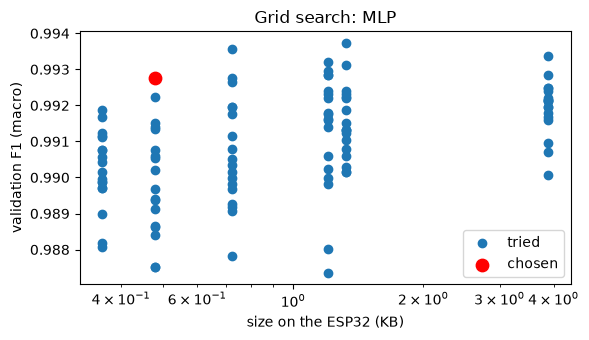

best val F1 0.9937 -> chosen {'layers': (16, 8), 'dropout': 0.0, 'activation': 'relu', 'learning_rate': 0.003} (val F1 0.9928, 0.5 KB)
all tries saved to results/tuning/mlp.csv


In [264]:
# Grid search: MLP
# n_layers      : number of hidden layers
# neurons       : number of neurons in every hidden layer
#                 e.g. n_layers=2, neurons=16  ->  20 inputs -> 16 -> 16 -> 2 outputs
# dropout       : share of neurons switched off while training (against overfitting)
# activation    : "relu" or "tanh" (tanh needs "TANH" in TFLM_OPS, already added)
# learning_rate : step size of training      } training settings, see split_params()
# batch_size    : rows per training step     }
# The network is built by build_mlp(), which the MLP cell below uses too.
# Scored with the float32 model (faster); the int8 version is checked in the next cell.
# Size = number of weights (int8: ~1 byte each; the .tflite file adds ~2-3 KB).

def build_mlp(layers, dropout=0.0, activation="relu"):
    keras.utils.set_random_seed(SEED)    # same starting weights every time -> repeatable
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(N_FEATURES,)))                     # 20 preprocessed features
    for neurons in layers:                                          # one hidden layer per number
        model.add(keras.layers.Dense(neurons, activation=activation))
        if dropout > 0:
            model.add(keras.layers.Dropout(dropout))   # only active while training, removed for the ESP32
    model.add(keras.layers.Dense(N_CLASSES, activation="softmax"))  # probability of normal / attack
    return model
mlp_grid = {
    "layers": [
        (16,),           # 1 layer:  20 -> 16 -> 2
        (32,),
        (16, 8),         # 2 layers: 20 -> 16 -> 8 -> 2
        (32, 16),
        (32, 16, 8),     # 3 layers
        (64, 32, 16),
    ],
    "dropout":       [0.0, 0.1, 0.2],
    "activation":    ["relu", "tanh"],
    "learning_rate": [1e-3, 3e-3, 6e-3],
    # "batch_size":    [128, 256, 512],
}

def mlp_train_and_score(params):
    network, training = split_params(params)
    model = build_mlp(**network)
    train_keras(model, X_train, y_train, X_val, y_val,
                loss="sparse_categorical_crossentropy", class_weight=CLASS_WEIGHT, **training)
    y_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    return val_score(y_pred), model.count_params()

mlp_params = grid_search("MLP", mlp_grid, mlp_train_and_score)

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2609 (Dense)              │ (None, 16)             │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2610 (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2611 (Dense)              │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 490 (1.91 KB)

 Trainable params: 490 (1.91 KB)

 Non-trainable params: 0 (0.00 B)

trained 26 epochs in 4.7s, best val_loss = 0.0245


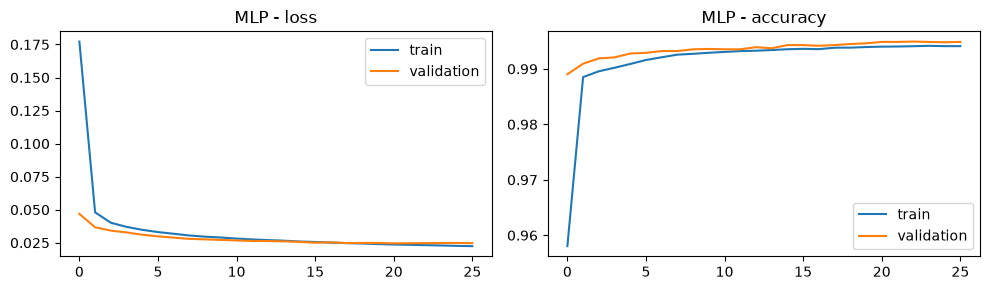

INFO:tensorflow:Assets written to: /tmp/tmp0fsulsw2/assets


INFO:tensorflow:Assets written to: /tmp/tmp0fsulsw2/assets


Saved artifact at '/tmp/tmp0fsulsw2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20), dtype=tf.float32, name='keras_tensor_12052')
Output Type:
  TensorSpec(shape=(1, 2), dtype=tf.float32, name=None)
Captures:
  140021440197840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021440195152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021440198224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021440196496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021440197072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021440195344: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/berat/Documents/Master/Models_tuning/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792632811.749113  217246 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792632811.749127  217246 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


MLP (int8): accuracy=0.9946  precision=0.9974  recall=0.9956  F1=0.9965  size=3.8 KB
compression: float32 accuracy 0.9949 -> int8 accuracy 0.9946
weights: float32 1960 bytes -> int8 ~490 bytes (the .tflite file is 3848 bytes incl. the network description)
TFLite operations used: ['FULLY_CONNECTED', 'SOFTMAX']


I0000 00:00:1792632811.749259  217246 reader.cc:83] Reading SavedModel from: /tmp/tmp0fsulsw2
I0000 00:00:1792632811.749424  217246 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792632811.749426  217246 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0fsulsw2
I0000 00:00:1792632811.750892  217246 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792632811.761598  217246 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp0fsulsw2
I0000 00:00:1792632811.764332  217246 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 15075 microseconds.
I0000 00:00:1792632811.947396  217246 flatbuffer_export.cc:4302] Estimated count of arithmetic ops: 1082  ops, equivalently 541  MACs
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
I0000 00:00:1792632811.960369  217246 flatbuffer_export.cc:4302] Estimated count of arithmetic ops: 1082  ops, equivalently 5

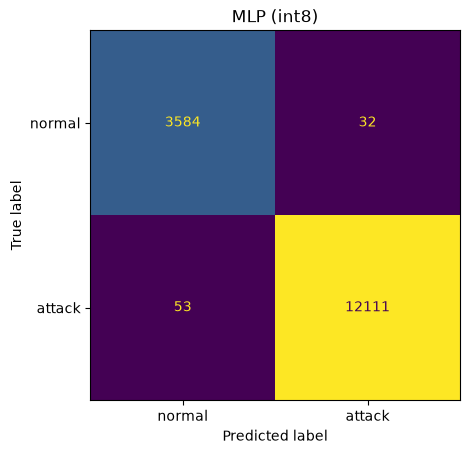

  -> exported to esp32/07_mlp


In [265]:
network, training = split_params(mlp_params)   # network settings / training settings
mlp = build_mlp(**network)                     # network from the grid search (see build_mlp above)
mlp.summary()

# 2) Train (float32) and show the learning curves
history, mlp_time = train_keras(mlp, X_train, y_train, X_val, y_val,
                                loss="sparse_categorical_crossentropy",   # labels are 0/1, not one-hot
                                class_weight=CLASS_WEIGHT, **training)
plot_history(history, "MLP")

# accuracy of the normal float32 model (before compression)
float_pred = mlp.predict(X_test, verbose=0).argmax(axis=1)
float_acc  = accuracy_score(y_test, float_pred)

# 3) Compress to int8 and evaluate the int8 model (= what runs on the ESP32)
mlp_bytes = to_int8_tflite(mlp, X_train)
mlp_tfl   = TFLiteModel(mlp_bytes)
y_pred    = mlp_tfl.predict(X_test)
int8_acc  = accuracy_score(y_test, y_pred)

evaluate("MLP (int8)", y_test, y_pred, mlp_time, mlp_tfl.predict, len(mlp_bytes),
         extra={"float32_accuracy": float_acc, "params": mlp.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {int8_acc:.4f}")
print(f"weights: float32 {mlp.count_params() * 4} bytes -> int8 ~{mlp.count_params()} bytes "
      f"(the .tflite file is {len(mlp_bytes)} bytes incl. the network description)")
print(f"TFLite operations used: {mlp_tfl.ops}")
plot_confusion_matrix("MLP (int8)")

# 4) Write the files into esp32/07_mlp
mlp_h = tflm_model_h(mlp_bytes, mlp_tfl, arena_kb=16,
                     extra="#define NN_IS_AUTOENCODER 0\n")   # 0 = classifier
export_project("07_mlp", "MLP_int8", mlp_h, y_pred)

### 6.2 1D-CNN

Grid search 1D-CNN: 60 combinations
trained 30 epochs in 7.4s, best val_loss = 0.1013
  {'conv_layers': (8,), 'dense_layers': (16,), 'kernel_size': 3, 'learning_rate': 0.001}  ->  val F1 0.9601   0.2 KB   (7.6s)
trained 30 epochs in 7.2s, best val_loss = 0.0596
  {'conv_layers': (8,), 'dense_layers': (16,), 'kernel_size': 3, 'learning_rate': 0.003}  ->  val F1 0.9757   0.2 KB   (7.4s)
trained 30 epochs in 7.1s, best val_loss = 0.0772
  {'conv_layers': (8,), 'dense_layers': (16,), 'kernel_size': 5, 'learning_rate': 0.001}  ->  val F1 0.9749   0.2 KB   (7.4s)
trained 30 epochs in 7.1s, best val_loss = 0.0448
  {'conv_layers': (8,), 'dense_layers': (16,), 'kernel_size': 5, 'learning_rate': 0.003}  ->  val F1 0.9845   0.2 KB   (7.4s)
trained 30 epochs in 7.0s, best val_loss = 0.2026
  {'conv_layers': (8,), 'dense_layers': (), 'kernel_size': 3, 'learning_rate': 0.001}  ->  val F1 0.8929   0.0 KB   (7.2s)
trained 30 epochs in 7.3s, best val_loss = 0.1820
  {'conv_layers': (8,), 'dense_layers

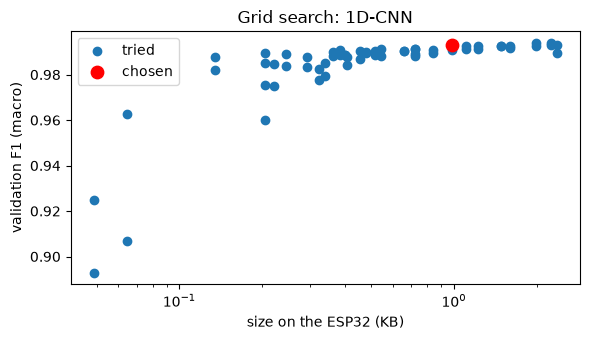

best val F1 0.9940 -> chosen {'conv_layers': (8, 16), 'dense_layers': (16,), 'kernel_size': 5, 'learning_rate': 0.003} (val F1 0.9932, 1.0 KB)
all tries saved to results/tuning/1dcnn.csv


In [266]:
def build_cnn(conv_layers, dense_layers=(16,), kernel_size=3):
    keras.utils.set_random_seed(SEED)    # same starting weights every time -> repeatable
    model = keras.Sequential(name="cnn1d")
    model.add(keras.Input(shape=(N_FEATURES, 1)))                   # 20 values, 1 channel
    for i, filters in enumerate(conv_layers):                       # one convolution layer per number
        model.add(keras.layers.Conv1D(filters, kernel_size, padding="same", activation="relu"))
        if i < len(conv_layers) - 1:                                # between two convolution layers:
            model.add(keras.layers.MaxPooling1D(2))                 #   keep the max of every 2 values
    model.add(keras.layers.GlobalAveragePooling1D())                # average over the positions
    for neurons in dense_layers:                                    # one Dense layer per number
        model.add(keras.layers.Dense(neurons, activation="relu"))
    model.add(keras.layers.Dense(N_CLASSES, activation="softmax"))  # normal / attack
    return model

cnn_grid = {
    "conv_layers": [
        (8,),            # 1 convolution layer with 8 filters
        (4, 8),          # 2 layers: 4 filters, then 8
        (8, 8),
        (8, 16),
        (8, 16, 16),
    ],
    "dense_layers": [
        (16,),           # 1 Dense layer of 16 neurons
        (),
        (16, 8),       # 2 Dense layers
    ],
    "kernel_size":   [3, 5],
    "learning_rate": [1e-3, 3e-3],
    # "batch_size":    [128, 256, 512],
}

def cnn_train_and_score(params):
    network, training = split_params(params)
    model = build_cnn(**network)
    train_keras(model, X_train.reshape(-1, N_FEATURES, 1), y_train,
                X_val.reshape(-1, N_FEATURES, 1), y_val,
                loss="sparse_categorical_crossentropy", class_weight=CLASS_WEIGHT, **training)
    y_pred = model.predict(X_val.reshape(-1, N_FEATURES, 1), verbose=0).argmax(axis=1)
    return val_score(y_pred), model.count_params()

cnn_params = grid_search("1D-CNN", cnn_grid, cnn_train_and_score)

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_394 (Conv1D)             │ (None, 20, 8)          │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_197               │ (None, 10, 8)          │             0 │
│ (MaxPooling1D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_395 (Conv1D)             │ (None, 10, 16)         │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_197    │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2732 (Dense)              │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2733 (Dense)              │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,010 (3.95 KB)

 Trainable params: 1,010 (3.95 KB)

 Non-trainable params: 0 (0.00 B)

trained 23 epochs in 7.9s, best val_loss = 0.0194


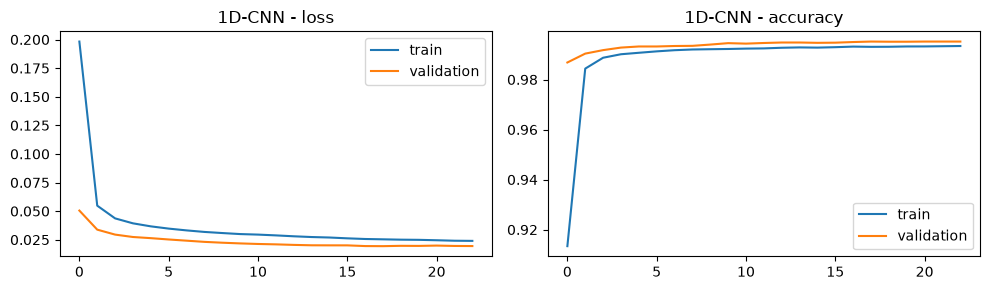

INFO:tensorflow:Assets written to: /tmp/tmpxj_fvjq6/assets


INFO:tensorflow:Assets written to: /tmp/tmpxj_fvjq6/assets


Saved artifact at '/tmp/tmpxj_fvjq6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20, 1), dtype=tf.float32, name='keras_tensor_13466')
Output Type:
  TensorSpec(shape=(1, 2), dtype=tf.float32, name=None)
Captures:
  140021468142800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021321595408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021321583120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021321589840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021398272528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021398268112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021321590416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021321590032: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/berat/Documents/Master/Models_tuning/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792633392.213885  217246 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792633392.213909  217246 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792633392.213990  217246 reader.cc:83] Reading SavedModel from: /tmp/tmpxj_fvjq6
I0000 00:00:1792633392.214297  217246 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792633392.214303  217246 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpxj_fvjq6
I0000 00:00:1792633392.216483  217246 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792633392.229347  217246 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpxj_fvjq6
I0000 00:00:1792633392.233128  217246 loader.cc:471] Sav

1D-CNN (int8): accuracy=0.9943  precision=0.9957  recall=0.9969  F1=0.9963  size=7.3 KB
compression: float32 accuracy 0.9946 -> int8 accuracy 0.9943
weights: float32 4040 bytes -> int8 ~1010 bytes (the .tflite file is 7472 bytes incl. the network description)
TFLite operations used: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'MEAN', 'RESHAPE', 'SOFTMAX']


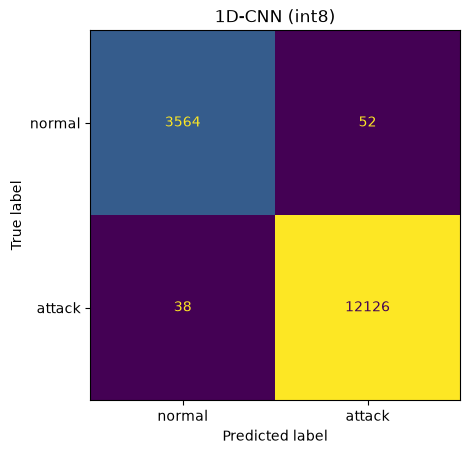

  -> exported to esp32/08_cnn1d


In [267]:
network, training = split_params(cnn_params)   # network settings / training settings
cnn = build_cnn(**network)                     # network from the grid search (see build_cnn above)
cnn.summary()

# the CNN needs shape (rows, 20, 1) instead of (rows, 20); the numbers are the same
X_train_cnn = X_train.reshape(-1, N_FEATURES, 1)
X_val_cnn   = X_val.reshape(-1, N_FEATURES, 1)
X_test_cnn  = X_test.reshape(-1, N_FEATURES, 1)

# 2) Train (float32) and show the learning curves
history, cnn_time = train_keras(cnn, X_train_cnn, y_train, X_val_cnn, y_val,
                                loss="sparse_categorical_crossentropy",
                                class_weight=CLASS_WEIGHT, **training)
plot_history(history, "1D-CNN")

# accuracy of the normal float32 model (before compression)
float_pred = cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)
float_acc  = accuracy_score(y_test, float_pred)

# 3) Compress to int8 and evaluate the int8 model (= what runs on the ESP32)
cnn_bytes = to_int8_tflite(cnn, X_train)       # reshapes to (1, 20, 1) by itself
cnn_tfl   = TFLiteModel(cnn_bytes)
y_pred    = cnn_tfl.predict(X_test)
int8_acc  = accuracy_score(y_test, y_pred)

evaluate("1D-CNN (int8)", y_test, y_pred, cnn_time, cnn_tfl.predict, len(cnn_bytes),
         extra={"float32_accuracy": float_acc, "params": cnn.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {int8_acc:.4f}")
print(f"weights: float32 {cnn.count_params() * 4} bytes -> int8 ~{cnn.count_params()} bytes "
      f"(the .tflite file is {len(cnn_bytes)} bytes incl. the network description)")
print(f"TFLite operations used: {cnn_tfl.ops}")
plot_confusion_matrix("1D-CNN (int8)")

# 4) Write the files into esp32/08_cnn1d
#    (a CNN needs more working memory than the MLP -> 24 KB arena)
cnn_h = tflm_model_h(cnn_bytes, cnn_tfl, arena_kb=24,
                     extra="#define NN_IS_AUTOENCODER 0\n")
export_project("08_cnn1d", "CNN1D_int8", cnn_h, y_pred)

### 6.3 Autoencoder anomaly detector (unsupervised)

Grid search Autoencoder: 72 combinations
trained 30 epochs in 2.4s, best val_loss = 0.2567
  {'layers': (8, 2), 'percentile': 85, 'learning_rate': 0.001}  ->  val F1 0.8606   0.4 KB   (2.6s)
trained 30 epochs in 2.3s, best val_loss = 0.1808
  {'layers': (8, 2), 'percentile': 85, 'learning_rate': 0.003}  ->  val F1 0.7596   0.4 KB   (2.6s)
  {'layers': (8, 2), 'percentile': 90, 'learning_rate': 0.001}  ->  val F1 0.5143   0.4 KB   (0.2s)
  {'layers': (8, 2), 'percentile': 90, 'learning_rate': 0.003}  ->  val F1 0.5684   0.4 KB   (0.2s)
  {'layers': (8, 2), 'percentile': 95, 'learning_rate': 0.001}  ->  val F1 0.2382   0.4 KB   (0.2s)
  {'layers': (8, 2), 'percentile': 95, 'learning_rate': 0.003}  ->  val F1 0.2383   0.4 KB   (0.2s)
  {'layers': (8, 2), 'percentile': 99, 'learning_rate': 0.001}  ->  val F1 0.1913   0.4 KB   (0.2s)
  {'layers': (8, 2), 'percentile': 99, 'learning_rate': 0.003}  ->  val F1 0.1942   0.4 KB   (0.2s)
trained 30 epochs in 2.4s, best val_loss = 0.1297
  {'layer

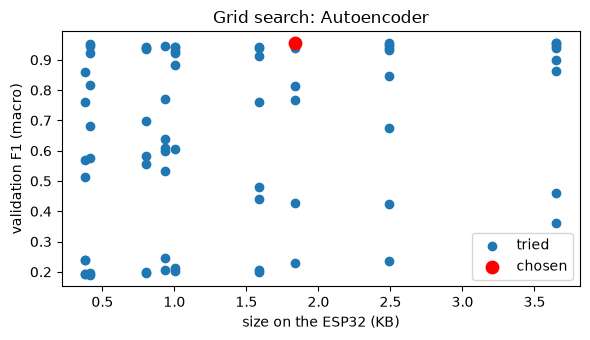

best val F1 0.9559 -> chosen {'layers': (32, 8), 'percentile': 90, 'learning_rate': 0.003} (val F1 0.9559, 1.8 KB)
all tries saved to results/tuning/autoencoder.csv


In [268]:
# Grid search: Autoencoder anomaly detector
# layers        : neurons per ENCODER layer; the last number is the bottleneck.
#                 The decoder is the same in reverse, e.g.
#                 (16, 8)    -> 20 -> 16 -> 8 -> 16 -> 20
#                 (16, 8, 4) -> 20 -> 16 -> 8 -> 4 -> 8 -> 16 -> 20
# percentile    : threshold = this percentile of the errors of NORMAL validation traffic
# learning_rate : step size of training      } training settings, see split_params()
# batch_size    : rows per training step     }
# Like K-Means, the network only learns from normal traffic, but choosing these
# settings uses the labels of the validation set.

def build_ae(layers):
    keras.utils.set_random_seed(SEED)    # same starting weights every time -> repeatable
    model = keras.Sequential(name="autoencoder")
    model.add(keras.Input(shape=(N_FEATURES,)))
    for neurons in layers:                                          # encoder (last one = bottleneck)
        model.add(keras.layers.Dense(neurons, activation="relu"))
    for neurons in reversed(layers[:-1]):                           # decoder = encoder in reverse
        model.add(keras.layers.Dense(neurons, activation="relu"))
    model.add(keras.layers.Dense(N_FEATURES, activation="linear"))  # rebuilt 20 features
    return model

ae_grid = {
    "layers": [
        (8, 2),          # 20 -> 8 -> 2 -> 8 -> 20
        (8, 4),
        (16, 4),
        (16, 8),         # (the network you had originally)
        (32, 8),
        (32, 4),
        (64, 8),
        (16, 8, 4),      # 3 encoder layers
        (32, 16, 4),
    ],
    "percentile":    [85, 90, 95, 99],
    "learning_rate": [1e-3, 3e-3],
    #"batch_size":    [128, 256, 512],
}

ae_trained = {}   # the percentile does not change the network -> train each network only once

def ae_train_and_score(params):
    network, training = split_params(params)
    percentile = network.pop("percentile")          # the threshold is not part of the network
    key = str(network) + str(training)              # e.g. "{'layers': (16, 4)}{'learning_rate': 0.001}"
    if key not in ae_trained:
        model = build_ae(**network)
        train_keras(model, X_train[y_train == 0], X_train[y_train == 0],
                    X_val[y_val == 0], X_val[y_val == 0], loss="mse", **training)
        ae_trained[key] = model
    model = ae_trained[key]

    errors = ((model.predict(X_val, verbose=0) - X_val) ** 2).mean(axis=1)
    threshold = np.percentile(errors[y_val == 0], percentile)
    return val_score((errors > threshold).astype(int)), model.count_params()

ae_params = grid_search("Autoencoder", ae_grid, ae_train_and_score)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2814 (Dense)              │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2815 (Dense)              │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2816 (Dense)              │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2817 (Dense)              │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,884 (7.36 KB)

 Trainable params: 1,884 (7.36 KB)

 Non-trainable params: 0 (0.00 B)

trained 30 epochs in 2.3s, best val_loss = 0.0085


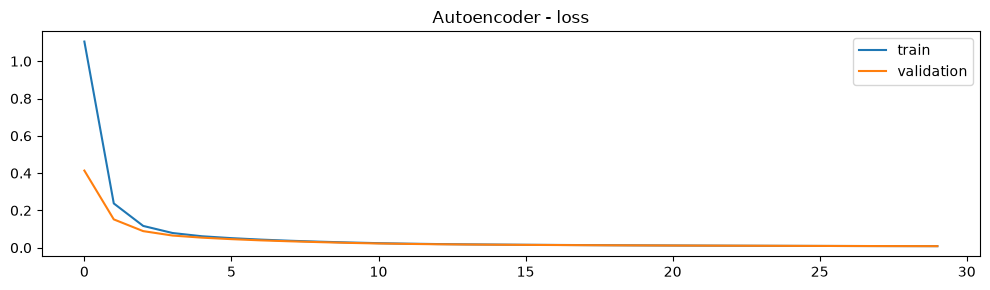

INFO:tensorflow:Assets written to: /tmp/tmpjc4_8jyf/assets


INFO:tensorflow:Assets written to: /tmp/tmpjc4_8jyf/assets


Saved artifact at '/tmp/tmpjc4_8jyf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 20), dtype=tf.float32, name='keras_tensor_13726')
Output Type:
  TensorSpec(shape=(1, 20), dtype=tf.float32, name=None)
Captures:
  140021577046096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140022178161552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485798608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485798224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485801680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485801488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485798992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140021485802064: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/berat/Documents/Master/Models_tuning/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792633451.609495  217246 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792633451.609513  217246 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792633451.609595  217246 reader.cc:83] Reading SavedModel from: /tmp/tmpjc4_8jyf
I0000 00:00:1792633451.609891  217246 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792633451.609895  217246 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpjc4_8jyf
I0000 00:00:1792633451.612059  217246 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792633451.624218  217246 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpjc4_8jyf
I0000 00:00:1792633451.627438  217246 loader.cc:471] Sav

Autoencoder (int8, anomaly): accuracy=0.9649  precision=0.9670  recall=0.9882  F1=0.9775  size=7.3 KB
compression: float32 accuracy 0.9647 -> int8 accuracy 0.9649
ROC-AUC = 0.962


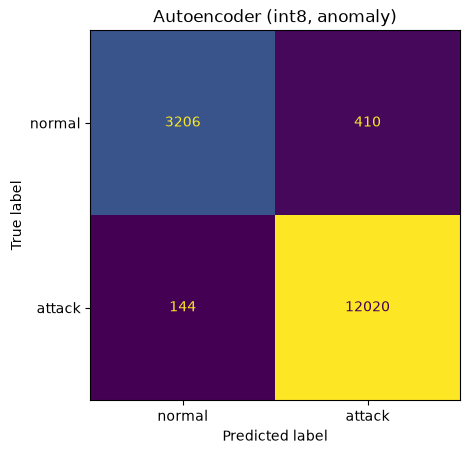

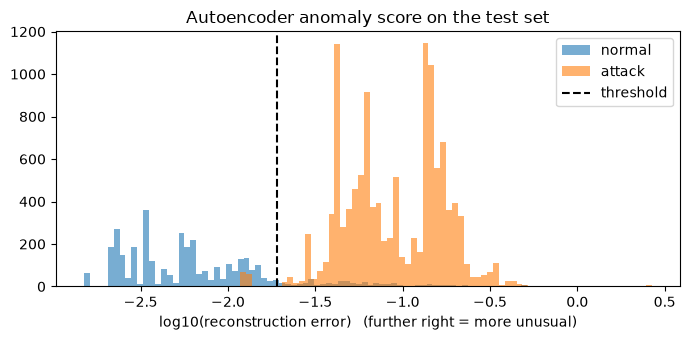

  -> exported to esp32/09_autoencoder


In [269]:
network, training = split_params(ae_params)    # network settings / training settings
AE_PERCENTILE = network.pop("percentile")      # threshold percentile (not part of the network)
ae = build_ae(**network)                       # network from the grid search
ae.summary()

# 2) Train on normal traffic only: input = target (it must copy itself)
X_train_normal = X_train[y_train == 0]
X_val_normal   = X_val[y_val == 0]
history, ae_time = train_keras(ae, X_train_normal, X_train_normal,
                               X_val_normal, X_val_normal, loss="mse", **training)
plot_history(history, "Autoencoder")

# 3) Compress to int8 (= what runs on the ESP32)
ae_bytes = to_int8_tflite(ae, X_train_normal)
ae_tfl   = TFLiteModel(ae_bytes)


def ae_score(X):
    """Anomaly score = reconstruction error of the int8 model (same as on the ESP32)."""
    rebuilt = ae_tfl.to_float(ae_tfl.raw_output(X))
    return ((rebuilt - X) ** 2).mean(axis=1)


def ae_predict(X):
    """1 (attack) if the reconstruction error is above the threshold, else 0 (normal)."""
    return (ae_score(X) > ae_threshold).astype(int)


# 4) Choose the threshold with NORMAL validation data (computed with the int8 model,
#    so it matches the ESP32 exactly)
ae_threshold = float(np.percentile(ae_score(X_val_normal), AE_PERCENTILE))

# 5) Evaluate on the test set
y_pred      = ae_predict(X_test)
test_scores = ae_score(X_test)
ae_auc      = roc_auc_score(y_test, test_scores)

# for comparison: the same detector with the float32 model (before compression)
def float_error(X):
    return ((ae.predict(X, verbose=0) - X) ** 2).mean(axis=1)

float_threshold = np.percentile(float_error(X_val_normal), AE_PERCENTILE)
float_acc = accuracy_score(y_test, (float_error(X_test) > float_threshold).astype(int))

evaluate("Autoencoder (int8, anomaly)", y_test, y_pred, ae_time, ae_predict, len(ae_bytes),
         extra={"float32_accuracy": float_acc, "threshold": ae_threshold,
                "roc_auc": ae_auc, "params": ae.count_params()})
print(f"compression: float32 accuracy {float_acc:.4f} -> int8 accuracy {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC = {ae_auc:.3f}")
plot_confusion_matrix("Autoencoder (int8, anomaly)")

# 6) Plot: reconstruction error of normal vs attack traffic
plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(test_scores[y_test == 0] + 1e-6), bins=80, alpha=0.6, label="normal")
plt.hist(np.log10(test_scores[y_test == 1] + 1e-6), bins=80, alpha=0.6, label="attack")
plt.axvline(np.log10(ae_threshold), color="k", linestyle="--", label="threshold")
plt.xlabel("log10(reconstruction error)   (further right = more unusual)")
plt.title("Autoencoder anomaly score on the test set")
plt.legend()
plt.tight_layout()
plt.show()

# 7) Write the files into esp32/09_autoencoder
ae_extra  = "#define NN_IS_AUTOENCODER 1\n"                               # 1 = anomaly detector
ae_extra += f"static const float AE_THRESHOLD = {c_float(ae_threshold)};\n"
ae_h = tflm_model_h(ae_bytes, ae_tfl, arena_kb=16, extra=ae_extra)
export_project("09_autoencoder", "Autoencoder_int8", ae_h, y_pred)

## 7. Comparison

### 7.0 Settings chosen by the grid search

In [284]:
# ---------------------------------------------------------------
# 7.0 Settings chosen by the grid search
# ---------------------------------------------------------------
chosen_table = pd.DataFrame([{"model": name, "chosen settings": str(params)}
                             for name, params in chosen_params.items()]).set_index("model")
chosen_table.to_csv(TUNING_DIR / "chosen_params.csv")
print(f"tuning score: F1 ({TUNING_AVERAGE}) on the validation set, "
      f"smallest model within {TUNING_TOLERANCE} of the best")
display(chosen_table)

tuning score: F1 (macro) on the validation set, smallest model within 0.001 of the best


,chosen settings
model,
Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 2}"
Random Forest,"{'n_estimators': 10, 'max_depth': 14}"
XGBoost,"{'n_estimators': 25, 'max_depth': 6, 'learning..."
Logistic Regression,"{'C': 1, 'l1_ratio': 0, 'solver': 'saga'}"
Linear SVM,{'C': 0.01}
RBF SVM,"{'C': 10, 'gamma': 0.1}"
Naive Bayes,{'var_smoothing': 0.001}
K-Means,"{'n_clusters': 64, 'percentile': 90, 'n_init':..."
MLP,"{'layers': (16, 8), 'dropout': 0.0, 'activatio..."


In [285]:
table = pd.DataFrame(results).set_index("model")

# columns in a logical order; a column only appears if at least one model has it
# (e.g. n_nodes only exists for the trees, roc_auc only for the anomaly detectors)
column_order = ["accuracy", "precision", "recall", "f1", "roc_auc",   # quality
                "float32_accuracy",                                  # NN before int8 compression
                "size_kb", "pc_infer_us", "train_time_s",            # cost
                "n_nodes", "depth", "params", "n_support_vectors",   # model size details
                "threshold"]                                         # anomaly detectors
columns = [col for col in column_order if col in table.columns]
table = table[columns]

# save for the thesis (open it in Excel / LibreOffice or use it for plots)
table.to_csv(RESULTS_DIR / "pc_results.csv")
print("saved", RESULTS_DIR / "pc_results.csv")

# show it: 4 decimals, empty cells instead of NaN, best F1 in dark green
display(table.style
        .format(precision=4, na_rep="")
        .background_gradient(subset=["f1"], cmap="Greens"))

saved results/pc_results.csv


,accuracy,precision,recall,f1,roc_auc,float32_accuracy,size_kb,pc_infer_us,train_time_s,n_nodes,depth,params,n_support_vectors,threshold
model,,,,,,,,,,,,,,
Decision Tree,0.9965,0.9973,0.9981,0.9977,,,3.9512,0.0639,0.1397,289.0000,10.0000,,,
Random Forest,0.9963,0.9973,0.9979,0.9976,,,47.7383,5.7026,0.0597,3486.0000,,,,
XGBoost,0.9972,0.9987,0.9977,0.9982,,,13.5488,0.9165,0.4951,1377.0000,,,,
Logistic Regression,0.9759,0.9884,0.9802,0.9843,,,0.0820,0.0513,1.8146,,,,,
Linear SVM,0.9758,0.9882,0.9803,0.9842,,,0.0820,0.0654,0.3706,,,,,
Naive Bayes,0.8795,0.9402,0.9010,0.9202,,,0.3203,0.1171,0.0108,,,,,
K-Means (anomaly),0.9642,0.9659,0.9884,0.9770,0.9675,,5.0039,0.2926,0.2143,,,,,0.3024
MLP (int8),0.9946,0.9974,0.9956,0.9965,,0.9949,3.7578,2.1517,4.7270,,,490.0000,,
1D-CNN (int8),0.9943,0.9957,0.9969,0.9963,,0.9946,7.2969,10.0075,7.8515,,,1010.0000,,


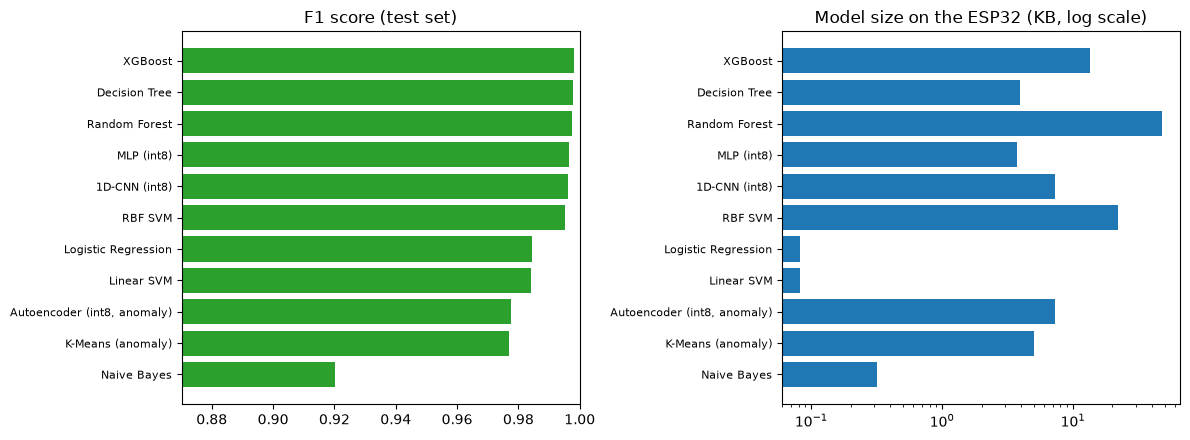

In [289]:
ranked = table.sort_values("f1")

fig, (ax_f1, ax_size) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) F1 score per model
ax_f1.barh(ranked.index, ranked["f1"], color="tab:green")
ax_f1.set_title("F1 score (test set)")
ax_f1.set_xlim(max(0, ranked["f1"].min() - 0.05), 1)   # zoom in so small differences are visible

# 2) Size on the ESP32 per model (log scale: from 0.08 KB to 40 KB)
ax_size.barh(ranked.index, ranked["size_kb"], color="tab:blue")
ax_size.set_xscale("log")
ax_size.set_title("Model size on the ESP32 (KB, log scale)")

ax_f1.tick_params(axis="y", labelsize=8)     # smaller model names so they fit
ax_size.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison.png", dpi=150)   # for the thesis
plt.show()

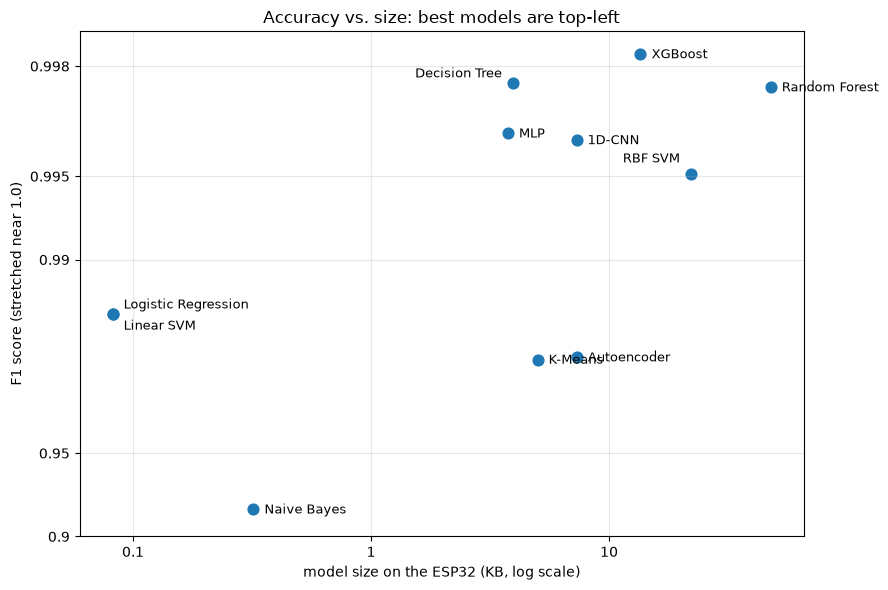

In [ ]:
# 7.2 Accuracy vs. size trade-off
fig, ax = plt.subplots(figsize=(9, 6))

error = 1 - table["f1"]
ax.scatter(table["size_kb"], error, s=60)

offsets = {"Decision Tree": (-8, 4), "Logistic Regression": (8, 4),
           "Linear SVM": (8, -11), "RBF SVM": (-8, 8)}
for name in table.index:
    dx, dy = offsets.get(name, (8, -3))
    short_name = name.split(" (")[0]                 # "MLP (int8)" -> "MLP"
    ax.annotate(short_name, (table.loc[name, "size_kb"], error[name]),
                xytext=(dx, dy), textcoords="offset points", fontsize=9,
                ha="right" if dx < 0 else "left")

ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_yaxis()                                    # high F1 at the top
ax.minorticks_off()
ax.set_xticks([0.1, 1, 10], ["0.1", "1", "10"])
f1_values = [ 0.9, 0.95, 0.99, 0.995, 0.998]
ax.set_yticks([1 - f for f in f1_values], [str(f) for f in f1_values])

ax.set_xlabel("model size on the ESP32 (KB, log scale)")
ax.set_ylabel("F1 score (stretched near 1.0)")
ax.set_title("Accuracy vs. size: best models are top-left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "tradeoff.png", dpi=150)
plt.show()